IMPORT LIBRARY

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import glob
import os

PENGOLAHAN DATA 1 BULAN (JULI)


In [ ]:

# Folder tempat file CSV berada
folder_path = r"D:\skripsi\Juli 2024"

# Kolom yang ingin diambil
columns_to_keep = ['timestamp', 'co2','bmp388Pressure','sht85Temp','atas','bawah']

# List untuk menyimpan setiap DataFrame sementara
dataframes = []

# Iterasi melalui semua file di folder
for file in os.listdir(folder_path):
    if file.endswith('.csv'):  # Hanya file dengan ekstensi .csv
        file_path = os.path.join(folder_path, file)
        
        # Baca file CSV
        df = pd.read_csv(file_path, usecols=columns_to_keep)
        
        # Tambahkan ke daftar
        dataframes.append(df)

# Gabungkan semua DataFrame
combined_df = pd.concat(dataframes, ignore_index=True)

# Pastikan kolom timestamp menjadi datetime
combined_df['timestamp'] = pd.to_datetime(combined_df['timestamp'])

# Tampilkan hasil
print(combined_df.head())

# Simpan hasil gabungan ke file baru jika diperlukan
combined_df.to_csv('data_juli.csv', index=False)


In [3]:
data_juli = pd.read_csv('data_juli.csv')

In [ ]:
data_juli.drop(columns= 'bmp388Pressure', inplace=True)

In [6]:
print(data_juli)

                       timestamp  sht85Temp  co2  bawah  atas
0        2024-07-01 00:06:01.361  24.829098  486    0.0  0.28
1        2024-07-01 00:06:01.499  24.786373  486    0.0  0.00
2        2024-07-01 00:06:01.648  24.773022  486    0.0  0.28
3        2024-07-01 00:06:01.799  24.855801  486    0.0  0.00
4        2024-07-01 00:06:01.948  24.799725  486    0.0  0.00
...                          ...        ...  ...    ...   ...
8769100  2024-07-31 23:36:00.543  24.463263  645    0.0  0.28
8769101  2024-07-31 23:36:00.694  24.447241  645    0.0  0.00
8769102  2024-07-31 23:36:00.846  24.404516  645    0.0  0.28
8769103  2024-07-31 23:36:00.997  24.391165  645    0.0  0.28
8769104  2024-07-31 23:36:01.149  24.447241  645    0.0  0.00

[8769105 rows x 5 columns]


In [7]:
# Menjadikan 'timestamp' sebagai indeks

data_juli.set_index('timestamp', inplace=True)

In [21]:
data_juli.index = pd.to_datetime(data_juli.index)

Menginterpolasi Tekanan

In [9]:
data_seminggu = pd.read_csv('gabungan_7hari.csv')

In [10]:
print(data_seminggu)

                       timestamp  bmp388Pressure  bmp388Temp   
0        2024-06-11T00:06:01.364       79.026558   24.340239  \
1        2024-06-11T00:06:01.439      101.172272   23.207165   
2        2024-06-11T00:06:01.601      101.174683   23.223057   
3        2024-06-11T00:06:01.763      101.174294   23.234293   
4        2024-06-11T00:06:01.925      101.174972   23.243816   
...                          ...             ...         ...   
1844516  2024-06-17T23:36:00.314      100.953239   24.910860   
1844517  2024-06-17T23:36:00.477      100.955185   24.910772   
1844518  2024-06-17T23:36:00.644      100.954712   24.912218   
1844519  2024-06-17T23:36:00.806      100.954559   24.913294   
1844520  2024-06-17T23:36:00.969      100.954575   24.913029   

         bmp388ApprxAltitude  sht85Humi  sht85Temp  co2  ch4     H2OSHT85   
0                  12.874734  98.419167  23.558025  632    0  2088.662261  \
1                  12.588780  98.347450  23.587399  632    0  2090.631146   


In [11]:
data_seminggu.eq (0).sum()

timestamp                    0
bmp388Pressure               0
bmp388Temp                   0
bmp388ApprxAltitude          0
sht85Humi                    0
sht85Temp                    0
co2                         68
ch4                    1844521
H2OSHT85                     0
utara                     4810
barat                  1161774
timur                  1444171
selatan                  40452
bawah                    88882
atas                   1735719
dtype: int64

In [12]:
data_seminggu['timestamp'] = pd.to_datetime(data_seminggu['timestamp'])
data_seminggu.set_index('timestamp', inplace=True)

In [26]:
# Tambahkan timestamp_mod untuk kedua DataFrame
data_seminggu['timestamp_mod'] = (data_seminggu.index - data_seminggu.index[0]) % pd.Timedelta(weeks=1)
data_juli['timestamp_mod'] = (data_juli.index - data_juli.index[0]) % pd.Timedelta(weeks=1)

# Gunakan interpolasi untuk memastikan semua nilai timestamp_mod tercakup
data_seminggu = data_seminggu.set_index('timestamp_mod').reindex(data_juli['timestamp_mod'].unique()).interpolate().reset_index()

# Gabungkan berdasarkan timestamp_mod
merged = pd.merge(
    data_juli.reset_index(),
    data_seminggu[['timestamp_mod', 'bmp388Pressure']],
    on='timestamp_mod',
    how='left'
)

# Kembalikan indeks ke timestamp dan hapus kolom tambahan
data_juli_bmp = merged.drop(columns=['timestamp_mod']).set_index('timestamp')

# Lihat hasilnya
print(data_juli_bmp.head())

                         sht85Temp  co2  bawah  atas  bmp388Pressure
timestamp                                                           
2024-07-01 00:06:01.361  24.829098  486    0.0  0.28       79.026558
2024-07-01 00:06:01.499  24.786373  486    0.0  0.00       79.057499
2024-07-01 00:06:01.648  24.773022  486    0.0  0.28       79.088439
2024-07-01 00:06:01.799  24.855801  486    0.0  0.00       79.119380
2024-07-01 00:06:01.948  24.799725  486    0.0  0.00       79.150321


In [ ]:
data_juli_bmp.isna().sum()

sht85Temp         53818
co2                   0
bawah                 0
atas                  0
bmp388Pressure        0
dtype: int64

C:\Users\User\AppData\Local\Temp\ipykernel_14424\2387912289.py:18: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


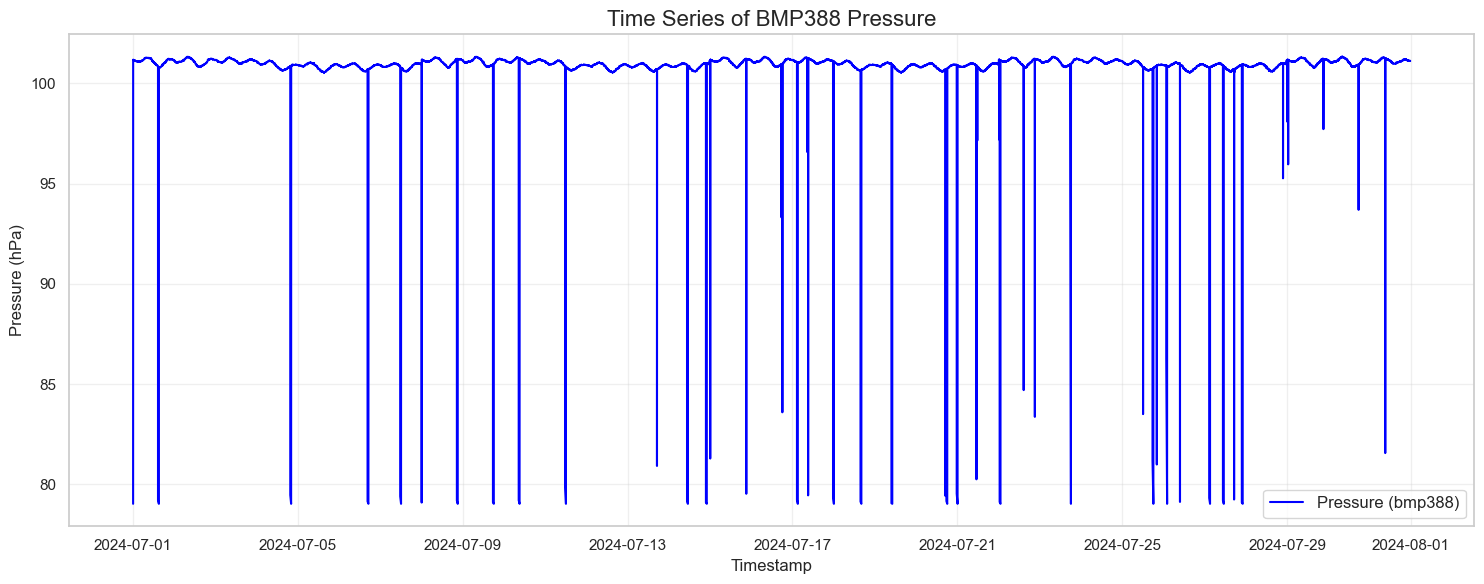

In [31]:
# Set gaya visualisasi Seaborn
sns.set(style="whitegrid")

# Membuat plot time series
plt.figure(figsize=(15, 6))  # Ukuran plot

# Plotting garis time series
plt.plot(data_juli_bmp.index, data_juli_bmp['bmp388Pressure'], label='Pressure (bmp388)', color='blue', linewidth=1.5)

# Tambahkan judul, label sumbu, dan legenda
plt.title('Time Series of BMP388 Pressure', fontsize=16)
plt.xlabel('Timestamp', fontsize=12)
plt.ylabel('Pressure (hPa)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)

# Tampilkan plot
plt.tight_layout()
plt.show()

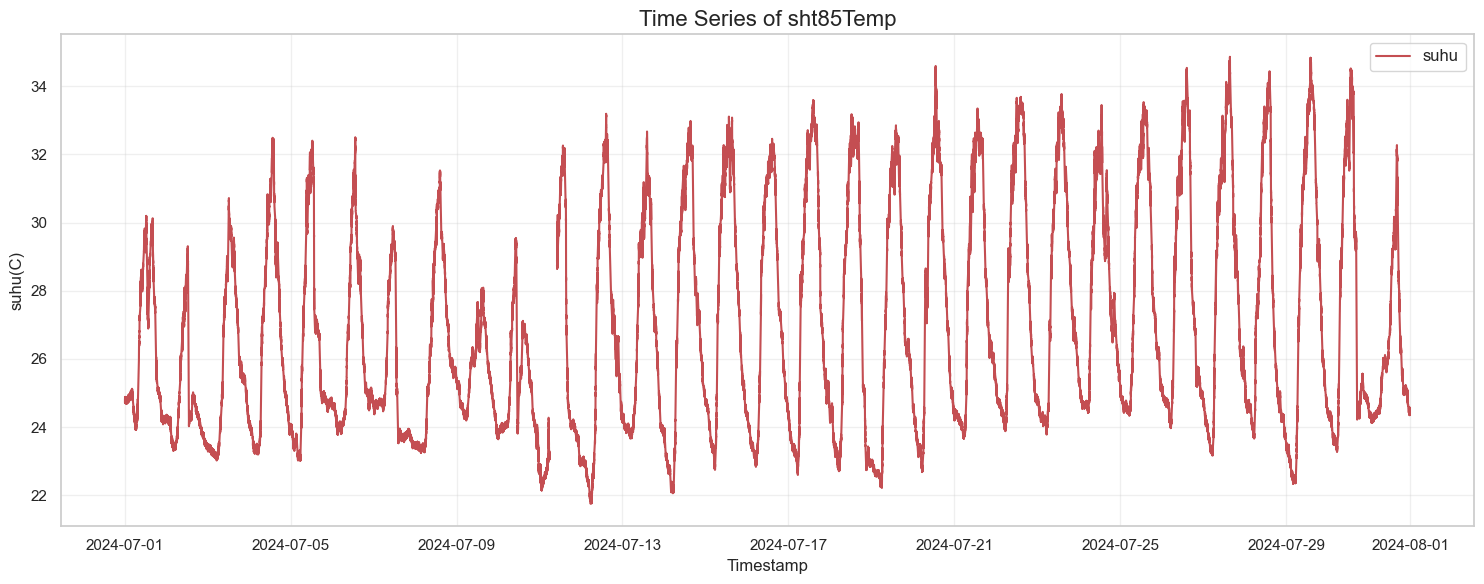

In [32]:
# Membuat plot time series
plt.figure(figsize=(15, 6))  # Ukuran plot

# Plotting garis time series
plt.plot(data_juli_bmp.index, data_juli_bmp['sht85Temp'], label='suhu', color='r', linewidth=1.5)

# Tambahkan judul, label sumbu, dan legenda
plt.title('Time Series of sht85Temp', fontsize=16)
plt.xlabel('Timestamp', fontsize=12)
plt.ylabel('suhu(C)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)

# Tampilkan plot
plt.tight_layout()
plt.show()

In [33]:
# Lakukan interpolasi berbasis waktu
data_juli_bmp['sht85Temp'] = data_juli_bmp['sht85Temp'].interpolate(method='time')


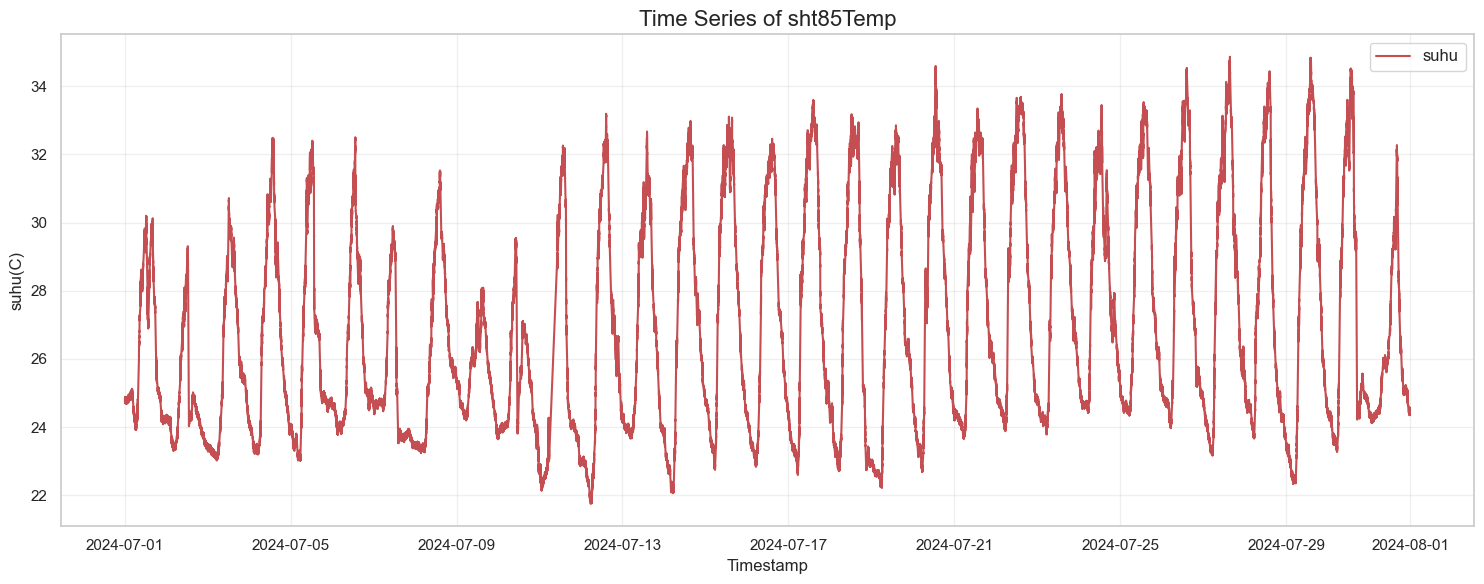

In [34]:
# Membuat plot time series
plt.figure(figsize=(15, 6))  # Ukuran plot

# Plotting garis time series
plt.plot(data_juli_bmp.index, data_juli_bmp['sht85Temp'], label='suhu', color='r', linewidth=1.5)

# Tambahkan judul, label sumbu, dan legenda
plt.title('Time Series of sht85Temp', fontsize=16)
plt.xlabel('Timestamp', fontsize=12)
plt.ylabel('suhu(C)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)

# Tampilkan plot
plt.tight_layout()
plt.show()

In [35]:
data_juli_bmp.isna().sum()

sht85Temp         0
co2               0
bawah             0
atas              0
bmp388Pressure    0
dtype: int64

In [37]:
data_juli = data_juli_bmp
print (data_juli)

                         sht85Temp  co2  bawah  atas  bmp388Pressure
timestamp                                                           
2024-07-01 00:06:01.361  24.829098  486    0.0  0.28       79.026558
2024-07-01 00:06:01.499  24.786373  486    0.0  0.00       79.057499
2024-07-01 00:06:01.648  24.773022  486    0.0  0.28       79.088439
2024-07-01 00:06:01.799  24.855801  486    0.0  0.00       79.119380
2024-07-01 00:06:01.948  24.799725  486    0.0  0.00       79.150321
...                            ...  ...    ...   ...             ...
2024-07-31 23:36:00.543  24.463263  645    0.0  0.28      101.120453
2024-07-31 23:36:00.694  24.447241  645    0.0  0.00      101.120453
2024-07-31 23:36:00.846  24.404516  645    0.0  0.28      101.120453
2024-07-31 23:36:00.997  24.391165  645    0.0  0.28      101.120453
2024-07-31 23:36:01.149  24.447241  645    0.0  0.00      101.120453

[8769105 rows x 5 columns]


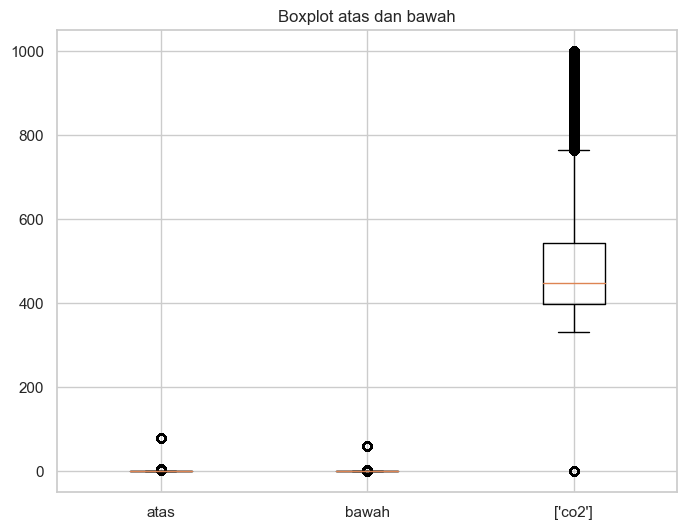

In [38]:
# Boxplot untuk melihat outlier
plt.figure(figsize=(8, 6))
plt.boxplot([data_juli['atas'], data_juli['bawah'],data_juli['co2']], labels=['atas', 'bawah',['co2']])
plt.title('Boxplot atas dan bawah')
plt.show()

In [49]:
data_juli_copy = data_juli.copy()

In [60]:
# Hitung z-score untuk variabel 'co2'
z_scores_var3 = np.abs(stats.zscore(data_juli_copy['co2']))

# Tentukan ambang batas z-score (biasanya 3 dianggap sebagai threshold)
threshold_1 = 3

# Ganti nilai outlier (z-score > threshold) dengan NaN
data_juli_copy['co2'] = np.where(z_scores_var3 > threshold_1, np.nan, data_juli_copy['co2'])

# Periksa hasil
print(data_juli_copy['co2'].isna().sum())  # Jumlah nilai yang diganti dengan NaN
print(data_juli_copy.head())

80688
                         sht85Temp    co2  bawah  atas  bmp388Pressure
timestamp                                                             
2024-07-01 00:06:01.361  24.829098  486.0    0.0  0.28       79.026558
2024-07-01 00:06:01.499  24.786373  486.0    0.0  0.00       79.057499
2024-07-01 00:06:01.648  24.773022  486.0    0.0  0.28       79.088439
2024-07-01 00:06:01.799  24.855801  486.0    0.0  0.00       79.119380
2024-07-01 00:06:01.948  24.799725  486.0    0.0  0.00       79.150321


In [52]:
# Kolom yang akan diproses
columns_to_process = ['atas', 'bawah']

for col in columns_to_process:
    # Hitung median untuk nilai yang <= 15
    median_value = data_juli_copy[col][data_juli_copy[col] <= 15].median()

    # Ganti nilai > 15 dengan median
    data_juli_copy[col] = data_juli_copy[col].where(data_juli_copy[col] <= 15, median_value)

# Periksa hasil
print(data_juli_copy.head())


                         sht85Temp  co2  bawah  atas  bmp388Pressure
timestamp                                                           
2024-07-01 00:06:01.361  24.829098  486    0.0  0.28       79.026558
2024-07-01 00:06:01.499  24.786373  486    0.0  0.00       79.057499
2024-07-01 00:06:01.648  24.773022  486    0.0  0.28       79.088439
2024-07-01 00:06:01.799  24.855801  486    0.0  0.00       79.119380
2024-07-01 00:06:01.948  24.799725  486    0.0  0.00       79.150321


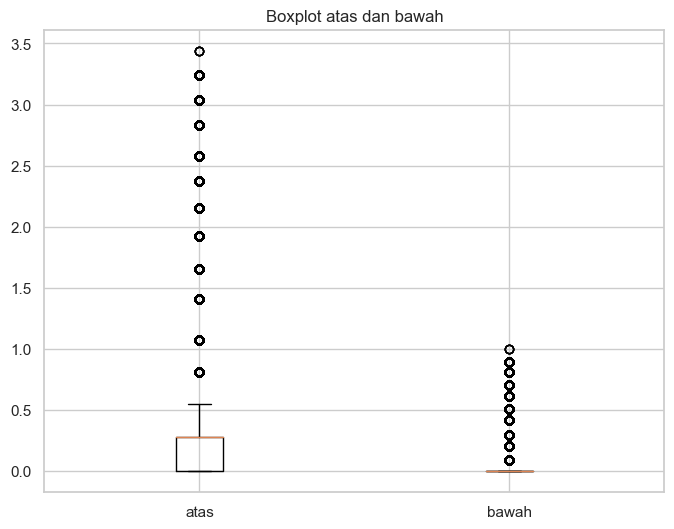

In [59]:
# Boxplot untuk melihat outlier
plt.figure(figsize=(8, 6))
plt.boxplot([data_juli_copy['atas'], data_juli_copy['bawah']], labels=['atas', 'bawah'])
plt.title('Boxplot atas dan bawah')
plt.show()

In [62]:
data_juli_copy.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8769105 entries, 2024-07-01 00:06:01.361000 to 2024-07-31 23:36:01.149000
Data columns (total 5 columns):
 #   Column          Dtype  
---  ------          -----  
 0   sht85Temp       float64
 1   co2             float64
 2   bawah           float64
 3   atas            float64
 4   bmp388Pressure  float64
dtypes: float64(5)
memory usage: 401.4 MB


In [65]:
# Konversi nilai ke numerik, mengubah nilai yang tidak dapat dikonversi menjadi NaN
data_juli_copy['co2'] = pd.to_numeric(data_juli_copy['co2'], errors='coerce')


In [66]:
# Interpolasi berbasis waktu
data_juli_copy['co2'] = data_juli_copy['co2'].interpolate(method='time')


In [67]:
# Ubah tipe data ke integer
data_juli_copy['co2'] = data_juli_copy['co2'].astype(int)


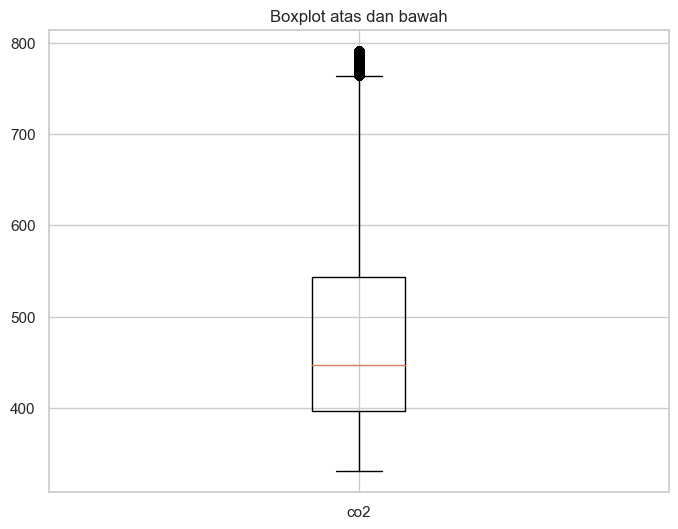

In [68]:
# Boxplot untuk melihat outlier
plt.figure(figsize=(8, 6))
plt.boxplot([data_juli_copy['co2']], labels=['co2'])
plt.title('Boxplot atas dan bawah')
plt.show()

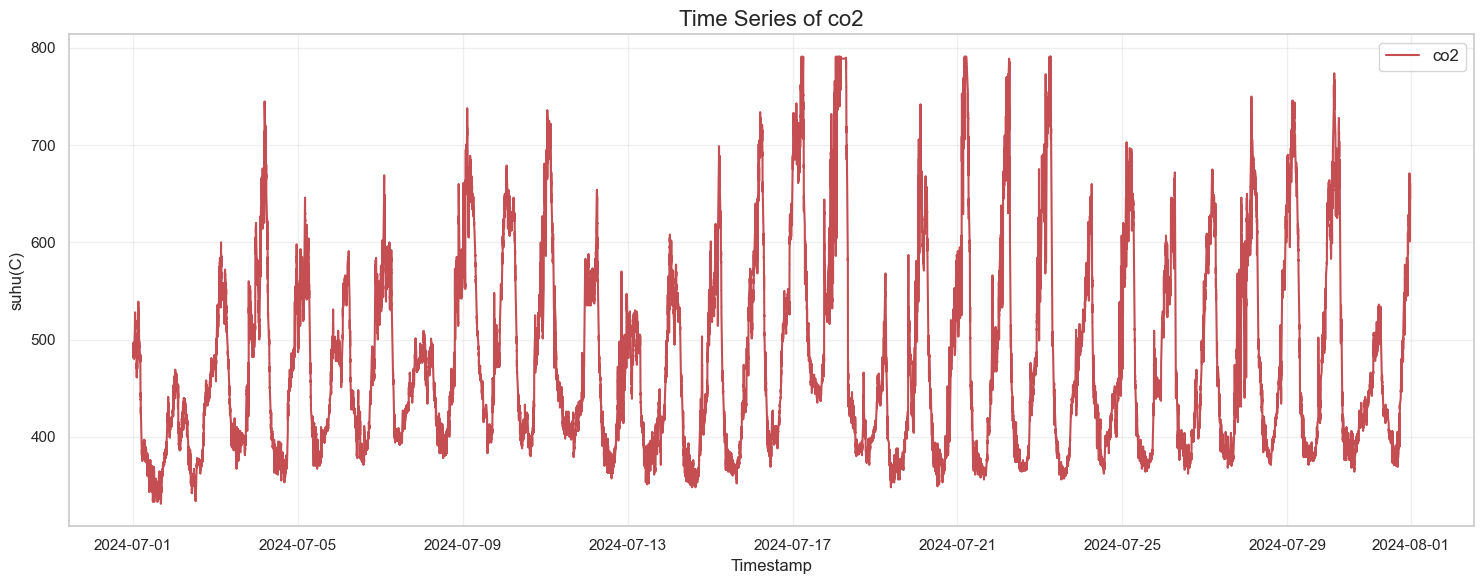

In [69]:
# Membuat plot time series
plt.figure(figsize=(15, 6))  # Ukuran plot

# Plotting garis time series
plt.plot(data_juli_copy.index, data_juli_copy['co2'], label='co2', color='r', linewidth=1.5)

# Tambahkan judul, label sumbu, dan legenda
plt.title('Time Series of co2', fontsize=16)
plt.xlabel('Timestamp', fontsize=12)
plt.ylabel('suhu(C)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)

# Tampilkan plot
plt.tight_layout()
plt.show()

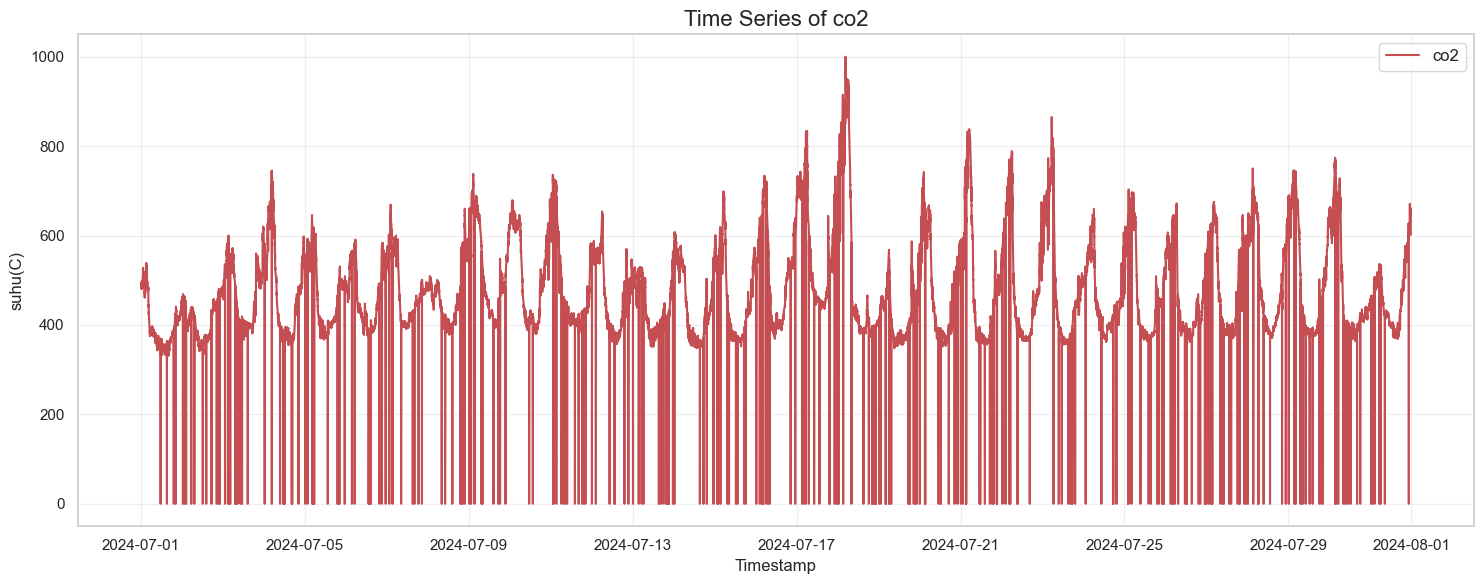

In [79]:
# Membuat plot time series
plt.figure(figsize=(15, 6))  # Ukuran plot

# Plotting garis time series
plt.plot(data_juli_bmp.index, data_juli_bmp['co2'], label='co2', color='r', linewidth=1.5)

# Tambahkan judul, label sumbu, dan legenda
plt.title('Time Series of co2', fontsize=16)
plt.xlabel('Timestamp', fontsize=12)
plt.ylabel('suhu(C)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)

# Tampilkan plot
plt.tight_layout()
plt.show()

In [70]:
# Membuat kolom 'w' (keceptan angin vertikal)
# Ubah tipe data menjadi float32
data_juli_copy['atas'] = data_juli_copy['atas'].astype('float32')
data_juli_copy['bawah'] = data_juli_copy['bawah'].astype('float32')

# Lalu jalankan operasi
data_juli_copy['w'] = np.where(
    (data_juli_copy['atas'] == 0) & (data_juli_copy['bawah'] == 0),
    0,
    np.where(data_juli_copy['atas'] > data_juli_copy['bawah'], data_juli_copy['atas'], -data_juli_copy['bawah'])
)

# Melihat hasil
print(data_juli_copy)

                         sht85Temp  co2  bawah  atas  bmp388Pressure     w
timestamp                                                                 
2024-07-01 00:06:01.361  24.829098  486    0.0  0.28       79.026558  0.28
2024-07-01 00:06:01.499  24.786373  486    0.0  0.00       79.057499  0.00
2024-07-01 00:06:01.648  24.773022  486    0.0  0.28       79.088439  0.28
2024-07-01 00:06:01.799  24.855801  486    0.0  0.00       79.119380  0.00
2024-07-01 00:06:01.948  24.799725  486    0.0  0.00       79.150321  0.00
...                            ...  ...    ...   ...             ...   ...
2024-07-31 23:36:00.543  24.463263  645    0.0  0.28      101.120453  0.28
2024-07-31 23:36:00.694  24.447241  645    0.0  0.00      101.120453  0.00
2024-07-31 23:36:00.846  24.404516  645    0.0  0.28      101.120453  0.28
2024-07-31 23:36:00.997  24.391165  645    0.0  0.28      101.120453  0.28
2024-07-31 23:36:01.149  24.447241  645    0.0  0.00      101.120453  0.00

[8769105 rows x 6 column

In [71]:
data_juli_copy.drop(columns=['bawah','atas'], inplace=True)

In [73]:
# Ubah tipe data menjadi float32
data_juli_copy['sht85Temp'] = data_juli_copy['sht85Temp'].astype('float32')
data_juli_copy['bmp388Pressure'] = data_juli_copy['bmp388Pressure'].astype('float32')

In [74]:
print(data_juli_copy)

                         sht85Temp  co2  bmp388Pressure     w
timestamp                                                    
2024-07-01 00:06:01.361  24.829098  486       79.026558  0.28
2024-07-01 00:06:01.499  24.786373  486       79.057495  0.00
2024-07-01 00:06:01.648  24.773022  486       79.088440  0.28
2024-07-01 00:06:01.799  24.855801  486       79.119377  0.00
2024-07-01 00:06:01.948  24.799725  486       79.150322  0.00
...                            ...  ...             ...   ...
2024-07-31 23:36:00.543  24.463263  645      101.120453  0.28
2024-07-31 23:36:00.694  24.447241  645      101.120453  0.00
2024-07-31 23:36:00.846  24.404516  645      101.120453  0.28
2024-07-31 23:36:00.997  24.391165  645      101.120453  0.28
2024-07-31 23:36:01.149  24.447241  645      101.120453  0.00

[8769105 rows x 4 columns]


In [75]:
# Hitung rata-rata rolling setiap 30 menit pada kolom 'w'
data_juli_copy.loc[:,'w_30m'] = data_juli_copy['w'].rolling('30T', closed='both').mean()

# hitung rata-rata rolling setiap 30 menit pada kolom co2
data_juli_copy.loc[:, 'co2_30m'] = data_juli_copy['co2'].rolling('30T',closed = 'both').mean()
print(data_juli_copy)

                         sht85Temp  co2  bmp388Pressure     w     w_30m   
timestamp                                                                 
2024-07-01 00:06:01.361  24.829098  486       79.026558  0.28  0.280000  \
2024-07-01 00:06:01.499  24.786373  486       79.057495  0.00  0.140000   
2024-07-01 00:06:01.648  24.773022  486       79.088440  0.28  0.186667   
2024-07-01 00:06:01.799  24.855801  486       79.119377  0.00  0.140000   
2024-07-01 00:06:01.948  24.799725  486       79.150322  0.00  0.112000   
...                            ...  ...             ...   ...       ...   
2024-07-31 23:36:00.543  24.463263  645      101.120453  0.28  0.202122   
2024-07-31 23:36:00.694  24.447241  645      101.120453  0.00  0.202105   
2024-07-31 23:36:00.846  24.404516  645      101.120453  0.28  0.202112   
2024-07-31 23:36:00.997  24.391165  645      101.120453  0.28  0.202118   
2024-07-31 23:36:01.149  24.447241  645      101.120453  0.00  0.202101   

                        

In [76]:
# Membuat kolom 'w_aksen' dan 'co2_aksen'
data_juli_copy.loc[:, 'w_aksen'] = data_juli_copy['w'] - data_juli_copy['w_30m']
data_juli_copy.loc[:, 'co2_aksen'] = data_juli_copy['co2'] - data_juli_copy['co2_30m']

# Membuat kolom 'NEE' sebagai hasil kali 'w_aksen' dan 'co2_aksen'
data_juli_copy.loc[:, 'NEE'] = data_juli_copy['w_aksen'] * data_juli_copy['co2_aksen']

# Melihat hasilnya
print(data_juli_copy)

                         sht85Temp  co2  bmp388Pressure     w     w_30m   
timestamp                                                                 
2024-07-01 00:06:01.361  24.829098  486       79.026558  0.28  0.280000  \
2024-07-01 00:06:01.499  24.786373  486       79.057495  0.00  0.140000   
2024-07-01 00:06:01.648  24.773022  486       79.088440  0.28  0.186667   
2024-07-01 00:06:01.799  24.855801  486       79.119377  0.00  0.140000   
2024-07-01 00:06:01.948  24.799725  486       79.150322  0.00  0.112000   
...                            ...  ...             ...   ...       ...   
2024-07-31 23:36:00.543  24.463263  645      101.120453  0.28  0.202122   
2024-07-31 23:36:00.694  24.447241  645      101.120453  0.00  0.202105   
2024-07-31 23:36:00.846  24.404516  645      101.120453  0.28  0.202112   
2024-07-31 23:36:00.997  24.391165  645      101.120453  0.28  0.202118   
2024-07-31 23:36:01.149  24.447241  645      101.120453  0.00  0.202101   

                        

In [77]:
# Misalkan data_juli_copy adalah DataFrame yang berisi kolom suhu dan tekanan udara
R = 8.314  # Konstanta gas ideal dalam J/(mol·K)

# Menghitung hasil dan membalikkan langsung
data_juli_copy['kepadatan_udara'] = 1 / (R * data_juli_copy['sht85Temp'] / data_juli_copy['bmp388Pressure'])

In [78]:
data_juli_copy['Fc'] = data_juli_copy['NEE'] * data_juli_copy['kepadatan_udara']
print (data_juli_copy)

                         sht85Temp  co2  bmp388Pressure     w     w_30m   
timestamp                                                                 
2024-07-01 00:06:01.361  24.829098  486       79.026558  0.28  0.280000  \
2024-07-01 00:06:01.499  24.786373  486       79.057495  0.00  0.140000   
2024-07-01 00:06:01.648  24.773022  486       79.088440  0.28  0.186667   
2024-07-01 00:06:01.799  24.855801  486       79.119377  0.00  0.140000   
2024-07-01 00:06:01.948  24.799725  486       79.150322  0.00  0.112000   
...                            ...  ...             ...   ...       ...   
2024-07-31 23:36:00.543  24.463263  645      101.120453  0.28  0.202122   
2024-07-31 23:36:00.694  24.447241  645      101.120453  0.00  0.202105   
2024-07-31 23:36:00.846  24.404516  645      101.120453  0.28  0.202112   
2024-07-31 23:36:00.997  24.391165  645      101.120453  0.28  0.202118   
2024-07-31 23:36:01.149  24.447241  645      101.120453  0.00  0.202101   

                        

In [80]:
# Menyimpan DataFrame ke dalam file CSV
data_juli_copy.to_csv('data_juli_selesai.csv')

In [82]:
data_juli_copy.drop(['w_30m','co2_30m', 'w_aksen', 'co2_aksen'], axis=1, inplace=True)

In [83]:
data_juli_copy.head()

,sht85Temp,co2,bmp388Pressure,w,NEE,kepadatan_udara,Fc
timestamp,,,,,,,
2024-07-01 00:06:01.361,24.829098,486,79.026558,0.28,0.0,0.382827,0.0
2024-07-01 00:06:01.499,24.786373,486,79.057495,0.00,-0.0,0.383637,-0.0
2024-07-01 00:06:01.648,24.773022,486,79.088440,0.28,0.0,0.383994,0.0
2024-07-01 00:06:01.799,24.855801,486,79.119377,0.00,-0.0,0.382865,-0.0
2024-07-01 00:06:01.948,24.799725,486,79.150322,0.00,-0.0,0.383880,-0.0


In [84]:
# Resample NEE setiap 30 menit dengan rata-rata
Fc_detik = data_juli_copy['Fc'].resample('1T').mean()

print(Fc_detik)


timestamp
2024-07-01 00:06:00   -0.006853
2024-07-01 00:07:00   -0.010856
2024-07-01 00:08:00    0.008466
2024-07-01 00:09:00   -0.002851
2024-07-01 00:10:00    0.013261
                         ...   
2024-07-31 23:32:00    0.127500
2024-07-31 23:33:00    0.053607
2024-07-31 23:34:00    0.085363
2024-07-31 23:35:00    0.041526
2024-07-31 23:36:00    0.037352
Freq: T, Name: Fc, Length: 44611, dtype: float64


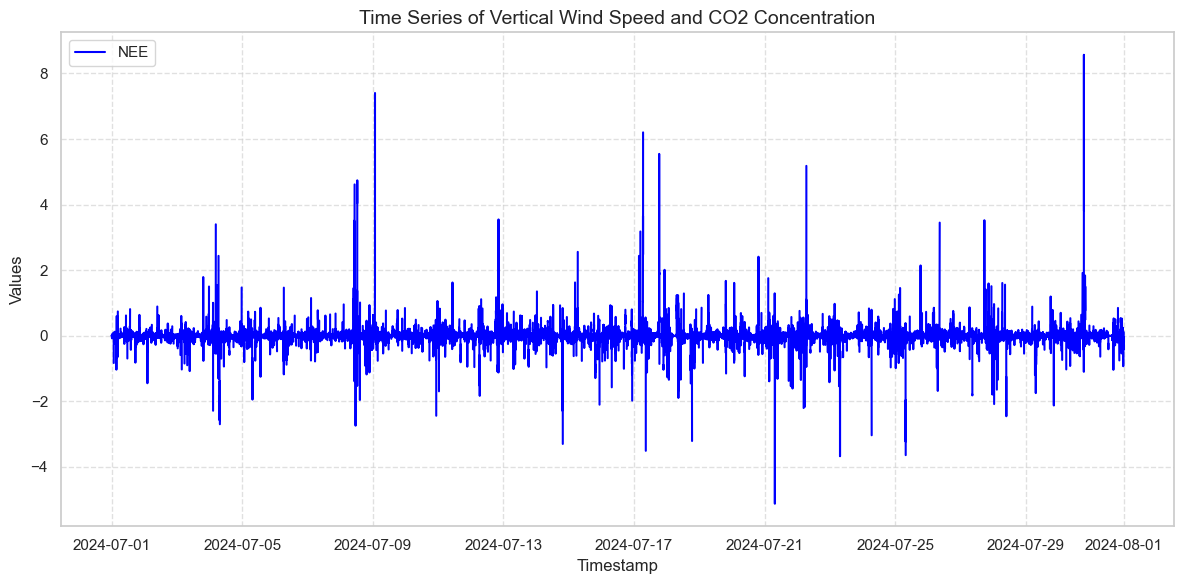

In [ ]:
# Membuat visualisasi time series
plt.figure(figsize=(12, 6))
plt.plot(Fc_detik, label='Fc', color='blue')

# Menambahkan detail
plt.title('Time Series of Vertical Wind Speed and CO2 Concentration', fontsize=14)
plt.xlabel('Timestamp', fontsize=12)
plt.ylabel('Values', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [86]:
Fc_detik.sum()

-57.88096804579728

PENGOLAHAN DATA 1 MINGGU (11 - 17 JUNI)

PEMBACAAN DATA


In [14]:
df = pd.read_csv('gabungan_7hari.csv')

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1844521 entries, 0 to 1844520
Data columns (total 15 columns):
 #   Column               Dtype  
---  ------               -----  
 0   timestamp            object 
 1   bmp388Pressure       float64
 2   bmp388Temp           float64
 3   bmp388ApprxAltitude  float64
 4   sht85Humi            float64
 5   sht85Temp            float64
 6   co2                  int64  
 7   ch4                  int64  
 8   H2OSHT85             float64
 9   utara                float64
 10  barat                float64
 11  timur                float64
 12  selatan              float64
 13  bawah                float64
 14  atas                 float64
dtypes: float64(12), int64(2), object(1)
memory usage: 211.1+ MB


In [20]:
df.head()

,timestamp,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas
0,2024-06-11T00:06:01.364,79.026558,98.419167,23.558025,632,0.0,0.0
1,2024-06-11T00:06:01.439,101.172272,98.347450,23.587399,632,0.0,0.0
2,2024-06-11T00:06:01.601,101.174683,98.393227,23.571377,632,0.0,0.0
3,2024-06-11T00:06:01.763,101.174294,98.315407,23.587399,632,0.0,0.0
4,2024-06-11T00:06:01.925,101.174972,98.388649,23.587399,632,0.0,0.0


Preprocessing Data


In [ ]:
#memilih variabel yang akan digunakan
df = df.iloc[:, [0,1,4,5,6,13,14]]

In [21]:
df


,timestamp,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas
0,2024-06-11T00:06:01.364,79.026558,98.419167,23.558025,632,0.00,0.0
1,2024-06-11T00:06:01.439,101.172272,98.347450,23.587399,632,0.00,0.0
2,2024-06-11T00:06:01.601,101.174683,98.393227,23.571377,632,0.00,0.0
3,2024-06-11T00:06:01.763,101.174294,98.315407,23.587399,632,0.00,0.0
4,2024-06-11T00:06:01.925,101.174972,98.388649,23.587399,632,0.00,0.0
...,...,...,...,...,...,...,...
1844516,2024-06-17T23:36:00.314,100.953239,94.857712,25.181582,506,5.27,0.0
1844517,2024-06-17T23:36:00.477,100.955185,94.857712,25.141527,506,5.27,0.0
1844518,2024-06-17T23:36:00.644,100.954712,94.898911,25.181582,506,5.27,0.0
1844519,2024-06-17T23:36:00.806,100.954559,94.804306,25.168230,506,5.27,0.0


In [22]:
flux_c02 = df.copy()
print (flux_c02)

                       timestamp  bmp388Pressure  sht85Humi  sht85Temp  co2   
0        2024-06-11T00:06:01.364       79.026558  98.419167  23.558025  632  \
1        2024-06-11T00:06:01.439      101.172272  98.347450  23.587399  632   
2        2024-06-11T00:06:01.601      101.174683  98.393227  23.571377  632   
3        2024-06-11T00:06:01.763      101.174294  98.315407  23.587399  632   
4        2024-06-11T00:06:01.925      101.174972  98.388649  23.587399  632   
...                          ...             ...        ...        ...  ...   
1844516  2024-06-17T23:36:00.314      100.953239  94.857712  25.181582  506   
1844517  2024-06-17T23:36:00.477      100.955185  94.857712  25.141527  506   
1844518  2024-06-17T23:36:00.644      100.954712  94.898911  25.181582  506   
1844519  2024-06-17T23:36:00.806      100.954559  94.804306  25.168230  506   
1844520  2024-06-17T23:36:00.969      100.954575  94.859238  25.154879  506   

         bawah  atas  
0         0.00   0.0  
1    

Myesuaikan Tipe Data

In [23]:
# Mengonversi kolom 'timestamp' ke datetime
flux_c02['timestamp'] = pd.to_datetime(flux_c02['timestamp'])

# Menjadikan 'timestamp' sebagai indeks
flux_c02.set_index('timestamp', inplace=True)

print(flux_c02.info())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1844521 entries, 2024-06-11 00:06:01.364000 to 2024-06-17 23:36:00.969000
Data columns (total 6 columns):
 #   Column          Dtype  
---  ------          -----  
 0   bmp388Pressure  float64
 1   sht85Humi       float64
 2   sht85Temp       float64
 3   co2             int64  
 4   bawah           float64
 5   atas            float64
dtypes: float64(5), int64(1)
memory usage: 98.5 MB
None


Mencari Missing Value

In [24]:
flux_c02.isnull().sum()

bmp388Pressure    0
sht85Humi         0
sht85Temp         0
co2               0
bawah             0
atas              0
dtype: int64

In [25]:
nilai_nol = (flux_c02 == 0).sum()
print (nilai_nol)

bmp388Pressure          0
sht85Humi               0
sht85Temp               0
co2                    68
bawah               88882
atas              1735719
dtype: int64


Menghilangkan outlier

In [26]:
nilai_unik = flux_c02['atas'].value_counts()
print(nilai_unik)

atas
0.00     1735719
0.28      107145
0.55        1296
77.09        342
0.81          19
Name: count, dtype: int64


In [27]:
nilai_unik = flux_c02['bawah'].value_counts()
print(nilai_unik)

bawah
0.38     266336
6.13     156218
0.74     152269
6.35      95729
0.00      88882
5.94      85297
4.81      52651
3.60      49093
3.31      48758
4.60      47885
3.84      40565
5.71      39692
6.54      37426
3.05      33130
9.71      31408
4.11      30459
5.07      30413
9.53      30253
5.51      28270
7.10      25572
6.75      25374
9.39      24056
4.34      23223
9.85      22592
9.06      21489
5.27      21017
9.21      20002
8.20      19778
6.93      19270
8.88      18705
8.73      17743
8.04      17332
8.54      16176
8.39      16049
7.31      15339
7.84      15020
2.74      15005
7.68      14864
10.02     14353
7.48      13878
2.47      12227
10.46     11446
10.16     11245
2.13      11137
10.33     10531
1.84      10464
1.15       9383
1.47       8159
10.76      6648
10.92      5286
10.63      4971
11.05      1020
79.33       341
11.18        89
11.34         3
Name: count, dtype: int64


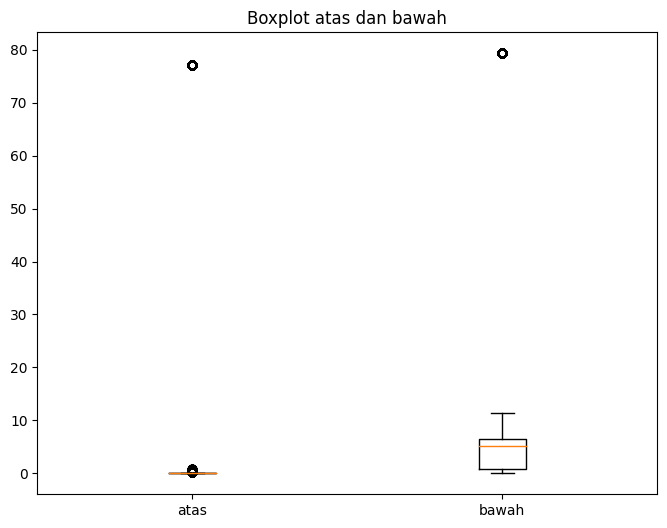

In [28]:
# Boxplot untuk melihat outlier
plt.figure(figsize=(8, 6))
plt.boxplot([flux_c02['atas'], flux_c02['bawah']], labels=['atas', 'bawah'])
plt.title('Boxplot atas dan bawah')
plt.show()

MENGHILANGKAN OUTLIER

In [29]:
# Hitung z-score untuk kedua variabel
z_scores_var1 = np.abs(stats.zscore(flux_c02['atas']))
z_scores_var2 = np.abs(stats.zscore(flux_c02['bawah']))

# Tentukan ambang batas z-score (biasanya 3)
threshold = 3

# Ganti outlier dengan rata-rata
median_var1 = flux_c02['atas'].median()
median_var2 = flux_c02['bawah'].median()

flux_c02['atas'] = np.where(z_scores_var1 > threshold, median_var1, flux_c02['atas'])
flux_c02['bawah'] = np.where(z_scores_var2 > threshold, median_var2, flux_c02['bawah'])


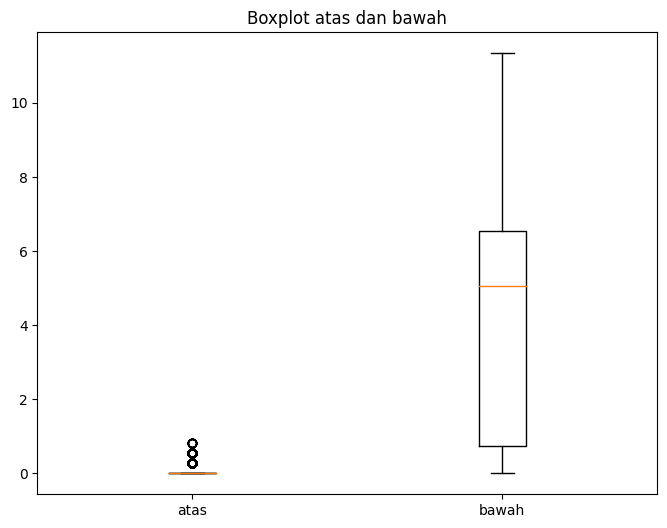

In [30]:
# Boxplot untuk melihat outlier
plt.figure(figsize=(8, 6))
plt.boxplot([flux_c02['atas'], flux_c02['bawah']], labels=['atas', 'bawah'])
plt.title('Boxplot atas dan bawah')
plt.show()

In [31]:
# Membuat kolom 'w' (keceptan angin vertikal)
flux_c02.loc[:, 'w'] = flux_c02.apply(
    lambda row: 0 if (row['atas'] == 0 and row['bawah'] == 0)  # Jika 'atas' dan 'bawah' sama-sama nol, isi dengan 0
    else row['atas'] if (row['atas'] > row['bawah'])           # Jika 'atas' lebih besar, ambil nilai 'atas'
    else -row['bawah'],                                        # Jika 'bawah' lebih besar, ambil nilai 'bawah' sebagai negatif
    axis=1
)

# Melihat hasil
print(flux_c02)

                         bmp388Pressure  sht85Humi  sht85Temp  co2  bawah   
timestamp                                                                   
2024-06-11 00:06:01.364       79.026558  98.419167  23.558025  632   0.00  \
2024-06-11 00:06:01.439      101.172272  98.347450  23.587399  632   0.00   
2024-06-11 00:06:01.601      101.174683  98.393227  23.571377  632   0.00   
2024-06-11 00:06:01.763      101.174294  98.315407  23.587399  632   0.00   
2024-06-11 00:06:01.925      101.174972  98.388649  23.587399  632   0.00   
...                                 ...        ...        ...  ...    ...   
2024-06-17 23:36:00.314      100.953239  94.857712  25.181582  506   5.27   
2024-06-17 23:36:00.477      100.955185  94.857712  25.141527  506   5.27   
2024-06-17 23:36:00.644      100.954712  94.898911  25.181582  506   5.27   
2024-06-17 23:36:00.806      100.954559  94.804306  25.168230  506   5.27   
2024-06-17 23:36:00.969      100.954575  94.859238  25.154879  506   5.27   

In [36]:
flux_c02

,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas,w
timestamp,,,,,,,
2024-06-11 00:06:01.364,79.026558,98.419167,23.558025,632,0.00,0.0,0.00
2024-06-11 00:06:01.439,101.172272,98.347450,23.587399,632,0.00,0.0,0.00
2024-06-11 00:06:01.601,101.174683,98.393227,23.571377,632,0.00,0.0,0.00
2024-06-11 00:06:01.763,101.174294,98.315407,23.587399,632,0.00,0.0,0.00
2024-06-11 00:06:01.925,101.174972,98.388649,23.587399,632,0.00,0.0,0.00
...,...,...,...,...,...,...,...
2024-06-17 23:36:00.314,100.953239,94.857712,25.181582,506,5.27,0.0,-5.27
2024-06-17 23:36:00.477,100.955185,94.857712,25.141527,506,5.27,0.0,-5.27
2024-06-17 23:36:00.644,100.954712,94.898911,25.181582,506,5.27,0.0,-5.27


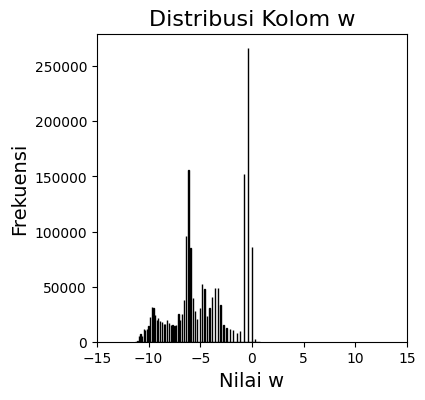

In [16]:


# Membuat histogram distribusi kolom 'w' dengan matplotlib
plt.figure(figsize=(4, 4))
plt.hist(flux_c02['w'], bins=500, color='skyblue', edgecolor='black')

# Menambahkan judul dan label
plt.title('Distribusi Kolom w', fontsize=16)
plt.xlabel('Nilai w', fontsize=14)
plt.ylabel('Frekuensi', fontsize=14)
plt.xlim(-15, 15)
# Menampilkan grafik
plt.show()

In [37]:
# Hitung rata-rata rolling setiap 30 menit pada kolom 'w'
flux_c02.loc[:,'w_30m'] = flux_c02['w'].rolling('30T', closed='both').mean()

# Tampilkan hasil
print(flux_c02.head())


                         bmp388Pressure  sht85Humi  sht85Temp  co2  bawah   
timestamp                                                                   
2024-06-11 00:06:01.364       79.026558  98.419167  23.558025  632    0.0  \
2024-06-11 00:06:01.439      101.172272  98.347450  23.587399  632    0.0   
2024-06-11 00:06:01.601      101.174683  98.393227  23.571377  632    0.0   
2024-06-11 00:06:01.763      101.174294  98.315407  23.587399  632    0.0   
2024-06-11 00:06:01.925      101.174972  98.388649  23.587399  632    0.0   

                         atas    w  w_30m  
timestamp                                  
2024-06-11 00:06:01.364   0.0  0.0    0.0  
2024-06-11 00:06:01.439   0.0  0.0    0.0  
2024-06-11 00:06:01.601   0.0  0.0    0.0  
2024-06-11 00:06:01.763   0.0  0.0    0.0  
2024-06-11 00:06:01.925   0.0  0.0    0.0  


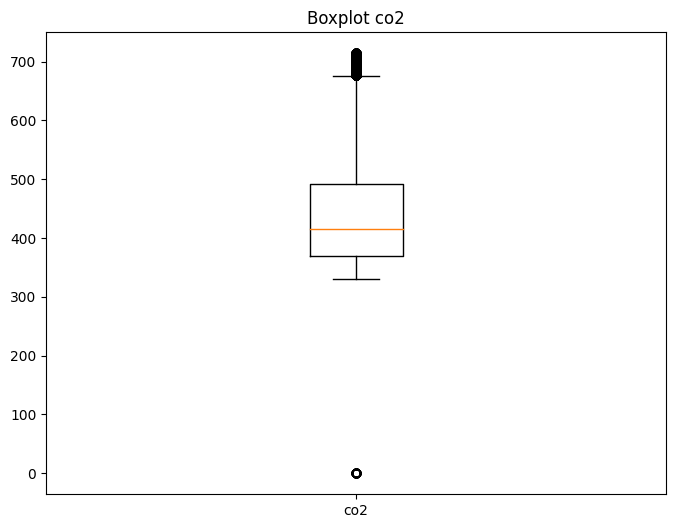

In [59]:
#Melihat Outlier pada data CO2 stasiun 1
plt.figure(figsize=(8, 6))
plt.boxplot([flux_c02['co2']], labels=['co2'])
plt.title('Boxplot co2')
plt.show()

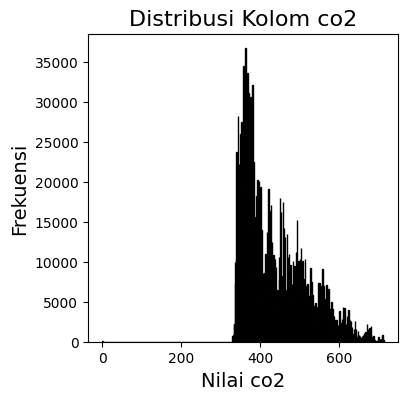

In [ ]:
#Melihat distribusi data
# Membuat histogram distribusi kolom 'co2' 
plt.figure(figsize=(4, 4))
plt.hist(flux_c02['co2'], bins=500, color='skyblue', edgecolor='black')

# Menambahkan judul dan label
plt.title('Distribusi Kolom co2', fontsize=16)
plt.xlabel('Nilai co2', fontsize=14)
plt.ylabel('Frekuensi', fontsize=14)

# Menampilkan grafik
plt.show()

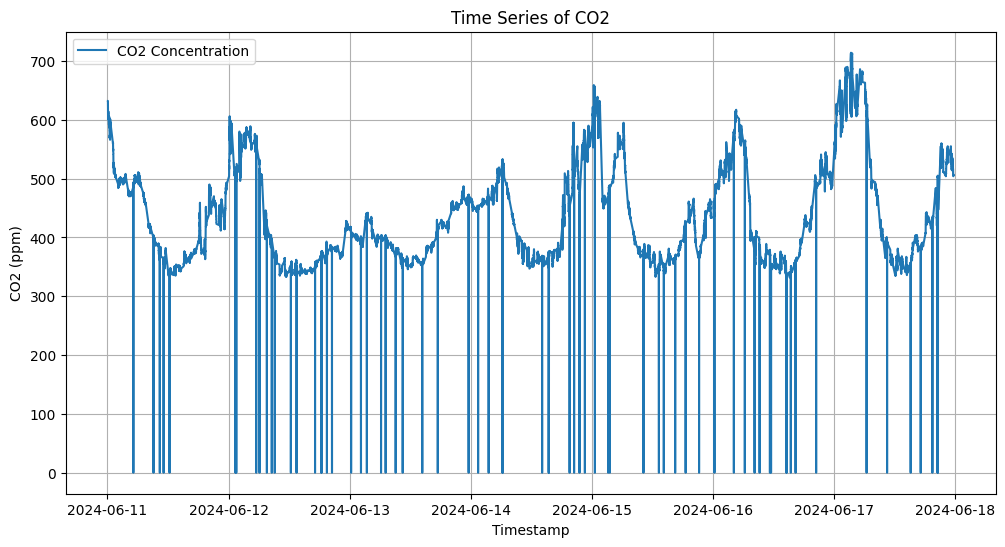

In [11]:
# Visualisasi sederhana
plt.figure(figsize=(12, 6))
plt.plot(flux_c02.index, flux_c02['co2'], label='CO2 Concentration')
plt.title('Time Series of CO2')
plt.xlabel('Timestamp')
plt.ylabel('CO2 (ppm)')
plt.legend()
plt.grid()
plt.show()

In [60]:
# Ganti nilai nol pada kolom 'co2' menjadi NaN
flux_c02['co2'] = flux_c02['co2'].replace(0, np.nan)

In [61]:
# Interpolasi secara linear
flux_c02['co2'] = flux_c02['co2'].interpolate(method='time')


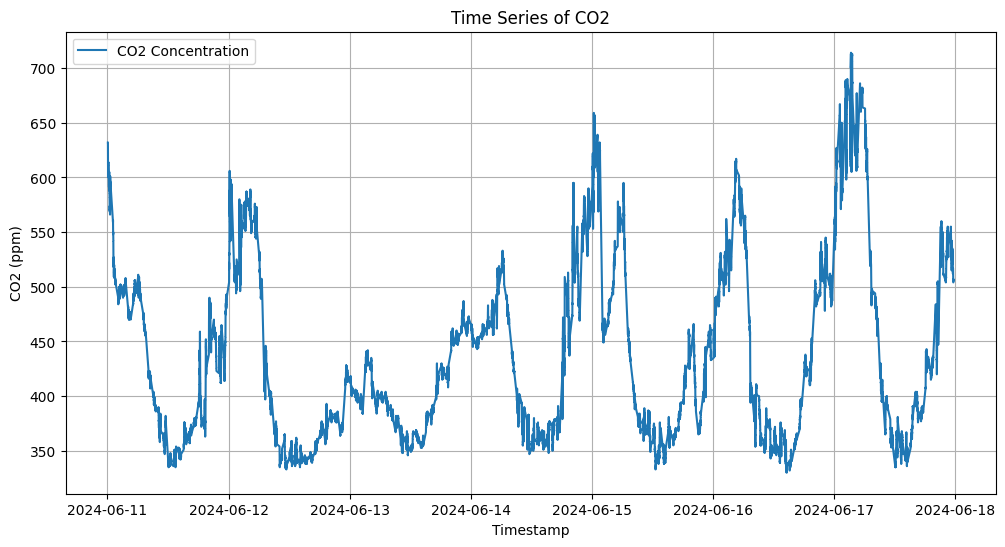

In [62]:
# Visualisasi sederhana
plt.figure(figsize=(12, 6))
plt.plot(flux_c02.index, flux_c02['co2'], label='CO2 Concentration')
plt.title('Time Series of CO2')
plt.xlabel('Timestamp')
plt.ylabel('CO2 (ppm)')
plt.legend()
plt.grid()
plt.show()

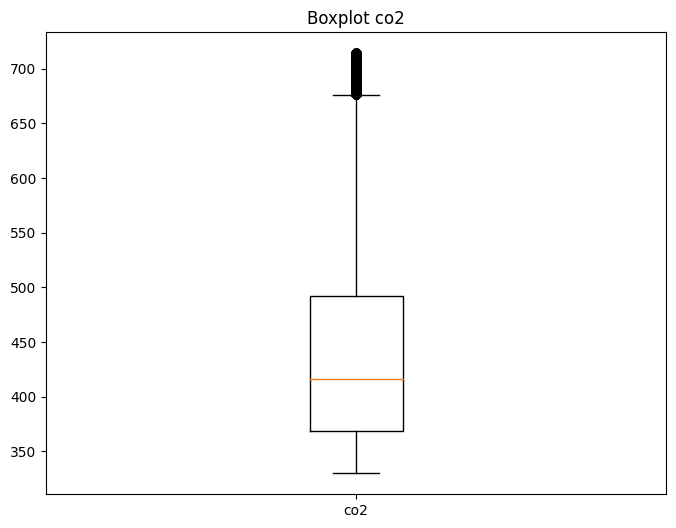

In [24]:
plt.figure(figsize=(8, 6))
plt.boxplot([flux_c02['co2']], labels=['co2'])
plt.title('Boxplot co2')
plt.show()

In [26]:
flux_c02.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1844521 entries, 2024-06-11 00:06:01.364000 to 2024-06-17 23:36:00.969000
Data columns (total 8 columns):
 #   Column          Dtype  
---  ------          -----  
 0   bmp388Pressure  float64
 1   sht85Humi       float64
 2   sht85Temp       float64
 3   co2             float64
 4   bawah           float64
 5   atas            float64
 6   w               float64
 7   w_30m           float64
dtypes: float64(8)
memory usage: 126.7 MB


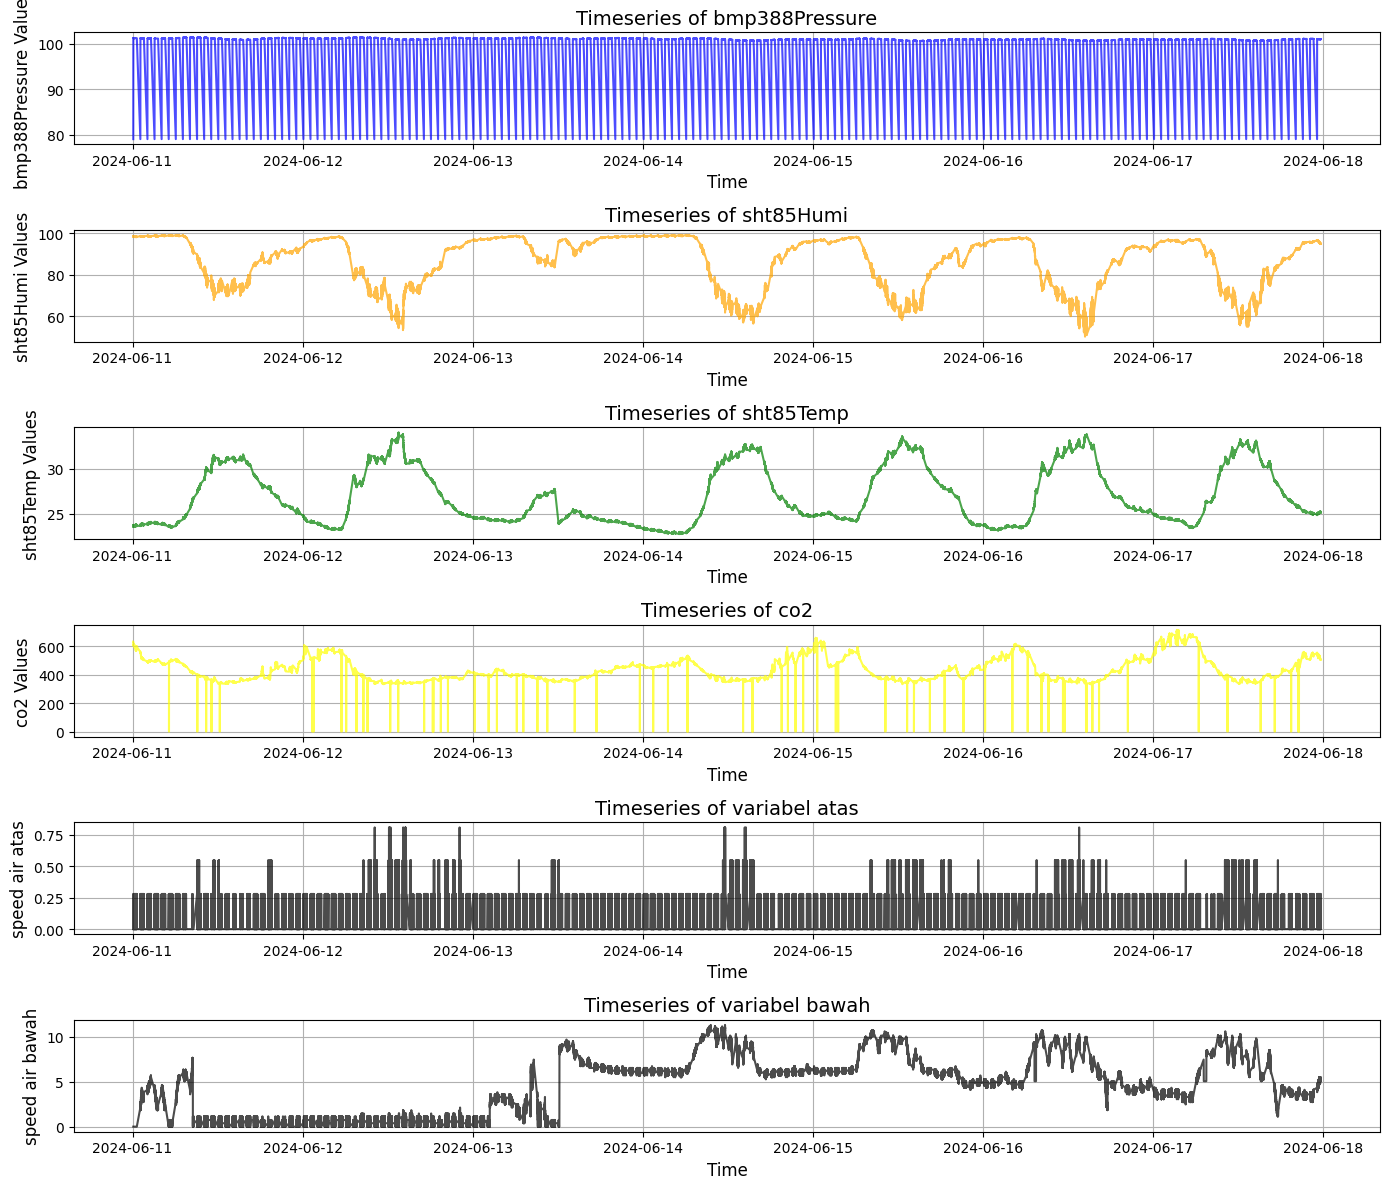

In [39]:
# Membuat plot dengan 3 subplots
plt.figure(figsize=(14, 12))

# Subplot 1: bmp388Pressure
plt.subplot(6, 1, 1)  # (jumlah baris, jumlah kolom, indeks subplot)
plt.plot(flux_c02.index, flux_c02['bmp388Pressure'], label='bmp388Pressure', color='blue', alpha=0.7)
plt.title('Timeseries of bmp388Pressure', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('bmp388Pressure Values', fontsize=12)
plt.grid(True)

# Subplot 2: sht85Humi
plt.subplot(6, 1, 2)
plt.plot(flux_c02.index, flux_c02['sht85Humi'], label='sht85Humi', color='orange', alpha=0.7)
plt.title('Timeseries of sht85Humi', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('sht85Humi Values', fontsize=12)
plt.grid(True)

# Subplot 3: sht85Temp
plt.subplot(6, 1, 3)
plt.plot(flux_c02.index, flux_c02['sht85Temp'], label='sht85Temp', color='green', alpha=0.7)
plt.title('Timeseries of sht85Temp', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('sht85Temp Values', fontsize=12)
plt.grid(True)

# Subplot 3: sht85Temp
plt.subplot(6, 1, 4)
plt.plot(flux_c02.index, flux_c02['co2'], label='co2', color='yellow', alpha=0.7)
plt.title('Timeseries of co2', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('co2 Values', fontsize=12)
plt.grid(True)

# Subplot 3: sht85Temp
plt.subplot(6, 1, 5)
plt.plot(flux_c02.index, flux_c02['atas'], label='atas', color='black', alpha=0.7)
plt.title('Timeseries of variabel atas', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air atas', fontsize=12)
plt.grid(True)

# Subplot 3: sht85Temp
plt.subplot(6, 1, 6)
plt.plot(flux_c02.index, flux_c02['bawah'], label='bawah', color='black', alpha=0.7)
plt.title('Timeseries of variabel bawah', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air bawah', fontsize=12)
plt.grid(True)
# Adjust layout for better spacing
plt.tight_layout()

# Tampilkan plot
plt.show()

Convert Mole Fraction ke Dry Mole Fraction

In [40]:
# Fungsi untuk menghitung tekanan uap jenuh (kPa)
def calc_p_H2O_sat(sht85Temp):
    return 0.61094 * np.exp((17.625 * sht85Temp ) / (sht85Temp + 243.04))

# Perhitungan Tekanan Uap Jenuh
flux_c02['p_H2O_sat'] = calc_p_H2O_sat(flux_c02['sht85Temp'])

# Mengubah nilai kelembapan relatif dari persentase ke bentuk desimal
flux_c02['RH_decimal'] = flux_c02['sht85Humi'] / 100

# Menghitung tekanan parsial uap air
flux_c02['p_H2O'] = flux_c02['RH_decimal'] * flux_c02['p_H2O_sat']

# Perhitungan Fraksi Mol Uap Air
flux_c02['x_H2O'] = flux_c02['p_H2O'] / flux_c02['bmp388Pressure']




In [63]:

# Perhitungan Fraksi Mol Udara Kering CO2
flux_c02['co2_dry'] = (flux_c02['co2']) / (1 - flux_c02['x_H2O'])

In [ ]:
#mengahpus kolom yang tidak digunakan
print (flux_c02.iloc[:, [3,8,9,10,13,14]])

                           co2  p_H2O_sat     p_H2O     x_H2O  RH_decimal   
timestamp                                                                   
2024-06-11 00:06:01.364  632.0   2.905574  2.859642  0.036186    0.984192  \
2024-06-11 00:06:01.439  632.0   2.910718  2.862617  0.028294    0.983475   
2024-06-11 00:06:01.601  632.0   2.907912  2.861188  0.028280    0.983932   
2024-06-11 00:06:01.763  632.0   2.910718  2.861685  0.028285    0.983154   
2024-06-11 00:06:01.925  632.0   2.910718  2.863816  0.028306    0.983886   
...                        ...        ...       ...       ...         ...   
2024-06-17 23:36:00.314  506.0   3.202097  3.037436  0.030088    0.948577   
2024-06-17 23:36:00.477  506.0   3.194476  3.030207  0.030015    0.948577   
2024-06-17 23:36:00.644  506.0   3.202097  3.038756  0.030100    0.948989   
2024-06-17 23:36:00.806  506.0   3.199555  3.033316  0.030046    0.948043   
2024-06-17 23:36:00.969  506.0   3.197015  3.032664  0.030040    0.948592   

In [41]:
kolom = flux_c02.iloc[:, [4,5,8,9,10,11,12,13]]
flux_c02.drop(kolom.columns, axis=1, inplace=True)
print (flux_c02)

                         bmp388Pressure  sht85Humi  sht85Temp    co2     w   
timestamp                                                                    
2024-06-11 00:06:01.364       79.026558  98.419167  23.558025  632.0  0.00  \
2024-06-11 00:06:01.439      101.172272  98.347450  23.587399  632.0  0.00   
2024-06-11 00:06:01.601      101.174683  98.393227  23.571377  632.0  0.00   
2024-06-11 00:06:01.763      101.174294  98.315407  23.587399  632.0  0.00   
2024-06-11 00:06:01.925      101.174972  98.388649  23.587399  632.0  0.00   
...                                 ...        ...        ...    ...   ...   
2024-06-17 23:36:00.314      100.953239  94.857712  25.181582  506.0 -5.27   
2024-06-17 23:36:00.477      100.955185  94.857712  25.141527  506.0 -5.27   
2024-06-17 23:36:00.644      100.954712  94.898911  25.181582  506.0 -5.27   
2024-06-17 23:36:00.806      100.954559  94.804306  25.168230  506.0 -5.27   
2024-06-17 23:36:00.969      100.954575  94.859238  25.154879  5

In [64]:
# hitung rata-rata rolling setiap 30 menit pada kolom co2_dry
flux_c02.loc[:, 'co2_dry_30m'] = flux_c02['co2_dry'].rolling('30T').mean()

In [65]:
# Membuat kolom 'w_aksen' dan 'co2_aksen'
flux_c02.loc[:, 'w_aksen'] = flux_c02['w'] - flux_c02['w_30m']
flux_c02.loc[:, 'co2_dry_aksen'] = flux_c02['co2_dry'] - flux_c02['co2_dry_30m']

# Membuat kolom 'rumus_1' sebagai hasil kali 'w_aksen' dan 'co2_aksen'
flux_c02.loc[:, 'rumus_1'] = flux_c02['w_aksen'] * flux_c02['co2_dry_aksen']



In [66]:
flux_c02

,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas,w,w_30m,p_H2O_sat,RH_decimal,p_H2O,x_H2O,co2_dry,co2_dry_30m,w_aksen,co2_dry_aksen,rumus_1,dry_pressure,rumus_2,Fec
timestamp,,,,,,,,,,,,,,,,,,,,
2024-06-11 00:06:01.364,79.026558,98.419167,23.558025,632.0,0.00,0.0,0.00,0.000000,2.899918,0.984192,2.854076,0.036115,655.680149,655.680149,0.000000,0.000000,0.000000,76.172482,0.388910,0.000000
2024-06-11 00:06:01.439,101.172272,98.347450,23.587399,632.0,0.00,0.0,0.00,0.000000,2.905056,0.983475,2.857049,0.028239,650.365973,653.023061,0.000000,-2.657088,-0.000000,98.315223,0.501338,-0.000000
2024-06-11 00:06:01.601,101.174683,98.393227,23.571377,632.0,0.00,0.0,0.00,0.000000,2.902253,0.983932,2.855620,0.028225,650.356073,652.134065,0.000000,-1.777992,-0.000000,98.319062,0.501698,-0.000000
2024-06-11 00:06:01.763,101.174294,98.315407,23.587399,632.0,0.00,0.0,0.00,0.000000,2.905056,0.983154,2.856118,0.028230,650.359437,651.690408,0.000000,-1.330971,-0.000000,98.318176,0.501353,-0.000000
2024-06-11 00:06:01.925,101.174972,98.388649,23.587399,632.0,0.00,0.0,0.00,0.000000,2.905056,0.983886,2.858245,0.028251,650.373385,651.427004,0.000000,-1.053618,-0.000000,98.316727,0.501346,-0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-06-17 23:36:00.314,100.953239,94.857712,25.181582,506.0,5.27,0.0,-5.27,-4.869498,3.196128,0.948577,3.031774,0.030031,521.666410,543.684233,-0.400502,-22.017824,8.818184,97.921465,0.467719,4.124431
2024-06-17 23:36:00.477,100.955185,94.857712,25.141527,506.0,5.27,0.0,-5.27,-4.869534,3.188514,0.948577,3.024551,0.029959,521.627623,543.682238,-0.400466,-22.054616,8.832120,97.930634,0.468508,4.137918
2024-06-17 23:36:00.644,100.954712,94.898911,25.181582,506.0,5.27,0.0,-5.27,-4.869570,3.196128,0.948989,3.033091,0.030044,521.673189,543.680248,-0.400430,-22.007059,8.812278,97.921621,0.467720,4.121675


VISULISASIKAN VARIABEL RUMUS_1

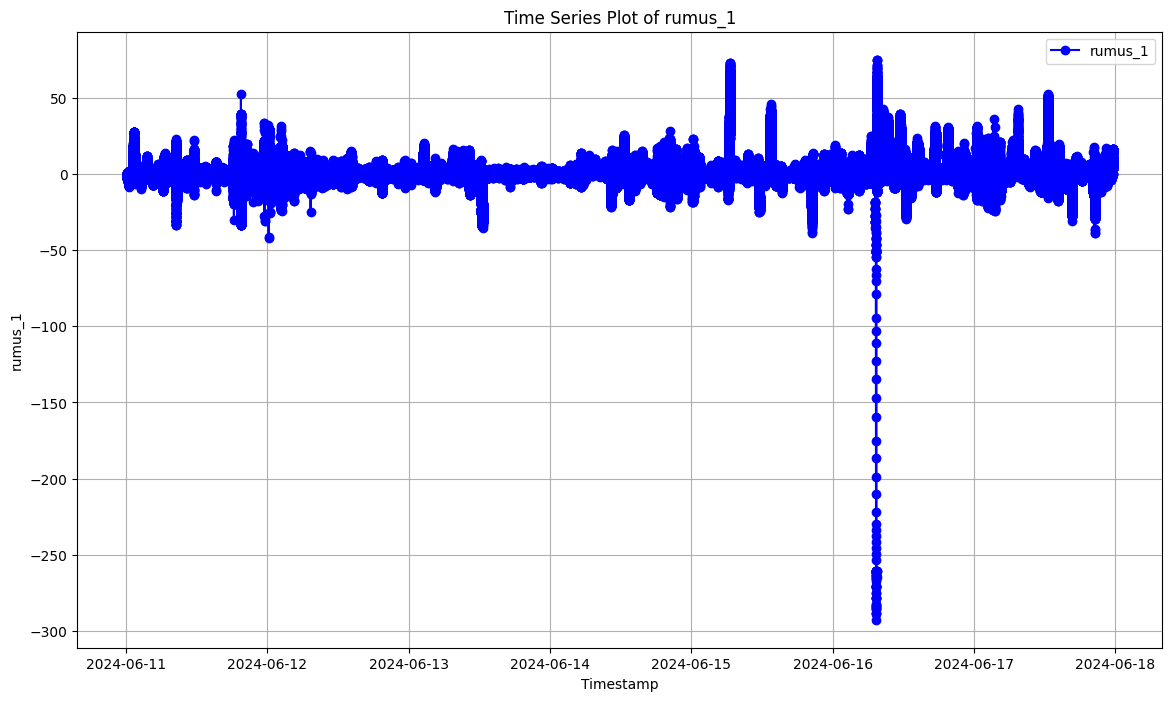

In [67]:

# Membuat plot garis waktu variabel rumus_1
plt.figure(figsize=(14, 8))
plt.plot(flux_c02.index, flux_c02['rumus_1'], label='rumus_1', color='blue', marker='o')

# Menambahkan judul dan label
plt.title('Time Series Plot of rumus_1')
plt.xlabel('Timestamp')
plt.ylabel('rumus_1')


plt.legend()
plt.grid(True)
plt.show()

MEMBUANG OUTLIER 

In [46]:

# Membuat salinan DataFrame asli
flux_c02_iqr = flux_c02.copy()

# Menghitung Q1, Q3, dan IQR
Q1 = flux_c02_iqr['rumus_1'].quantile(0.25)
Q3 = flux_c02_iqr['rumus_1'].quantile(0.75)
IQR = Q3 - Q1

# Menghilangkan outlier berdasarkan IQR
flux_c02_iqr = flux_c02_iqr[(flux_c02_iqr['rumus_1'] >= (Q1 - 1.5 * IQR)) & (flux_c02_iqr['rumus_1'] <= (Q3 + 1.5 * IQR))]


In [68]:
# Membuat salinan DataFrame asli
flux_c02_z = flux_c02.copy()

# Menghitung z-score variabel rumus_1
flux_c02_z['z_score'] = stats.zscore(flux_c02_z['rumus_1'])

# Menghilangkan outlier berdasarkan z-score
flux_c02_z = flux_c02_z[flux_c02_z['z_score'].abs() <= 5]

# Menghapus kolom z-score jika tidak diperlukan lagi
flux_c02_z = flux_c02_z.drop(columns='z_score')


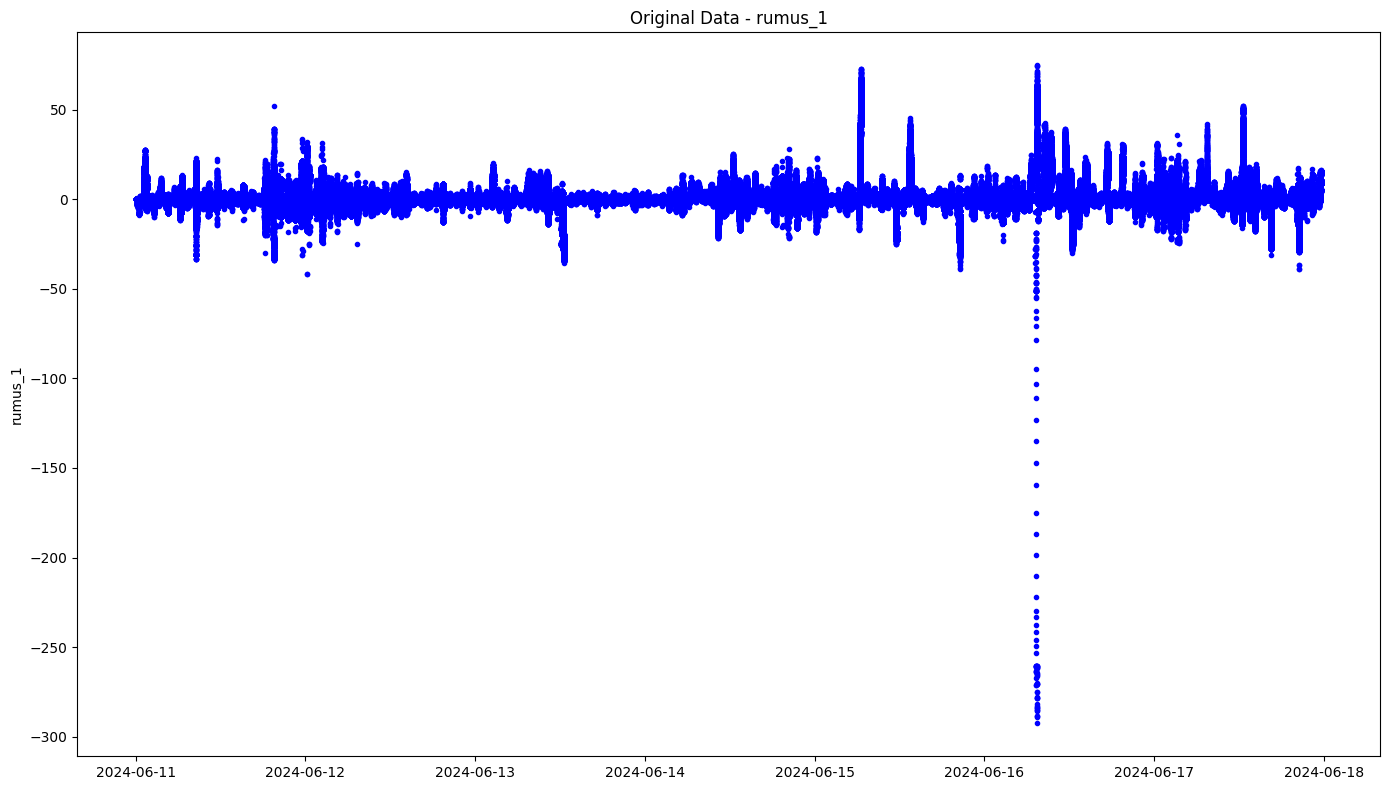

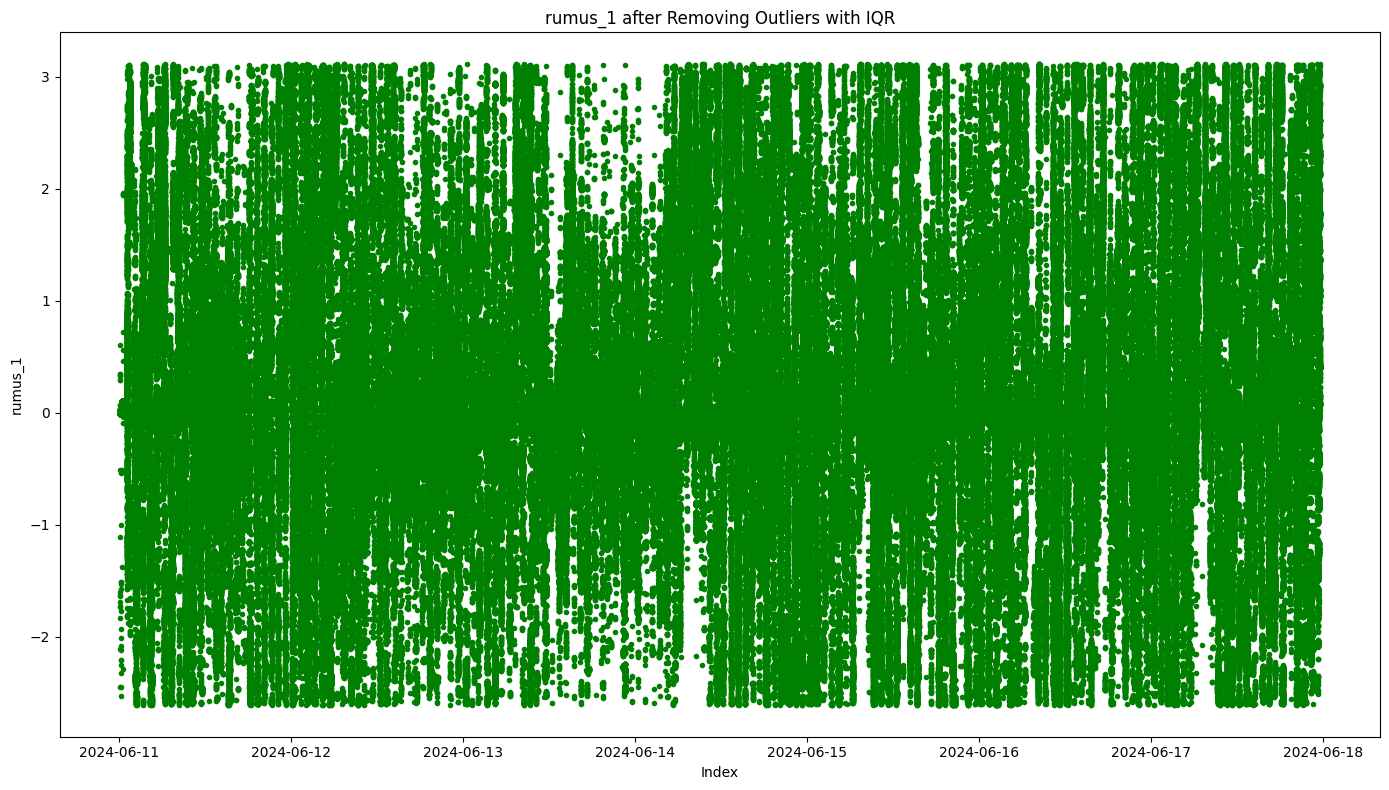

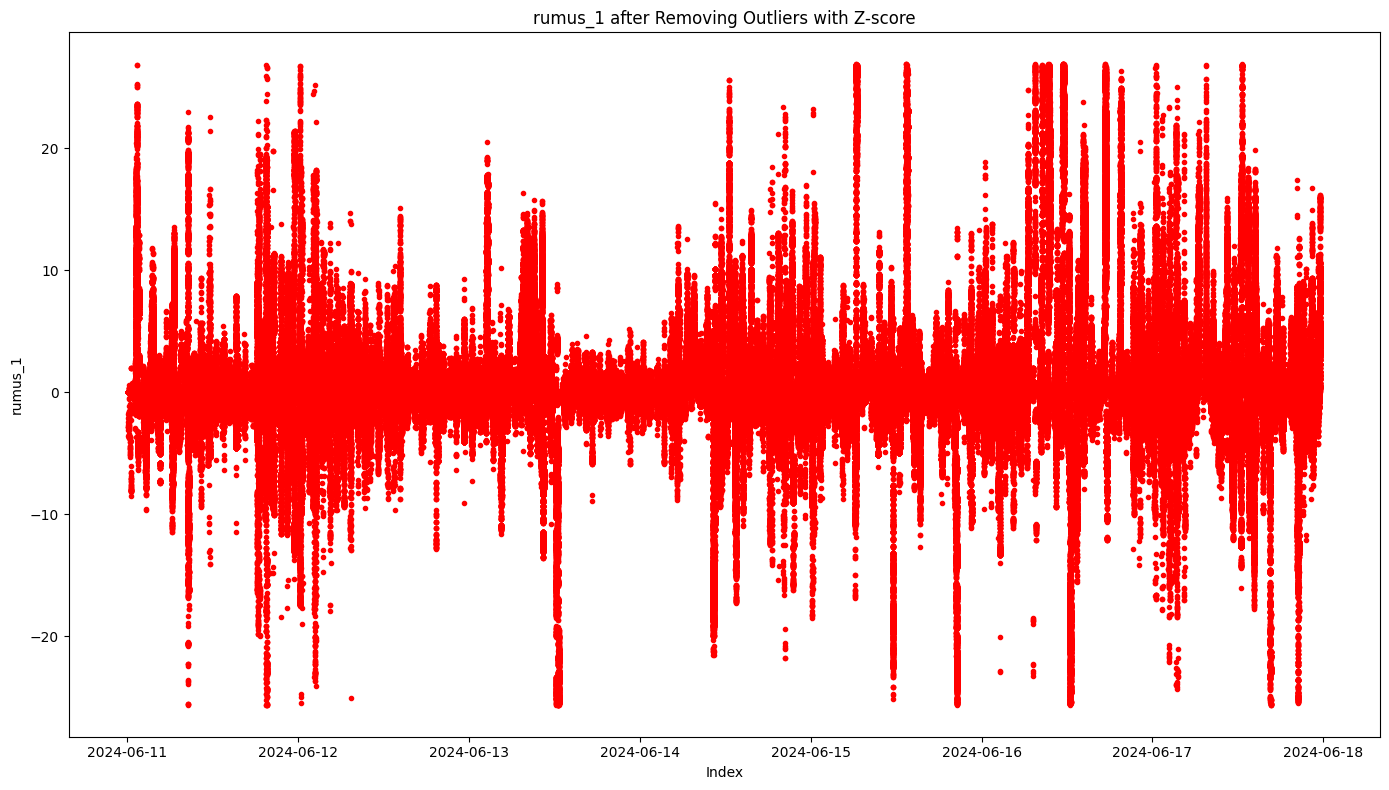

In [184]:
# Plot Sebelum dan Sesudah Penghilangan Outlier dengan Metode IQR
plt.figure(figsize=(14, 8))
plt.plot(flux_c02.index, flux_c02['rumus_1'], label='Original rumus_1', color='blue', marker='o', markersize=3, linestyle='none')
plt.title('Original Data - rumus_1')
plt.ylabel('rumus_1')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 8))
plt.plot(flux_c02_iqr.index, flux_c02_iqr['rumus_1'], label='rumus_1 after IQR', color='green', marker='o', markersize=3, linestyle='none')
plt.title('rumus_1 after Removing Outliers with IQR')
plt.ylabel('rumus_1')
plt.xlabel('Index')
plt.tight_layout()
plt.show()

# Plot Sebelum dan Sesudah Penghilangan Outlier dengan Metode Z-score
plt.figure(figsize=(14, 8))
plt.plot(flux_c02_z.index, flux_c02_z['rumus_1'], label='rumus_1 after Z-score', color='red', marker='o', markersize=3, linestyle='none')
plt.title('rumus_1 after Removing Outliers with Z-score')
plt.ylabel('rumus_1')
plt.xlabel('Index')
plt.tight_layout()
plt.show()


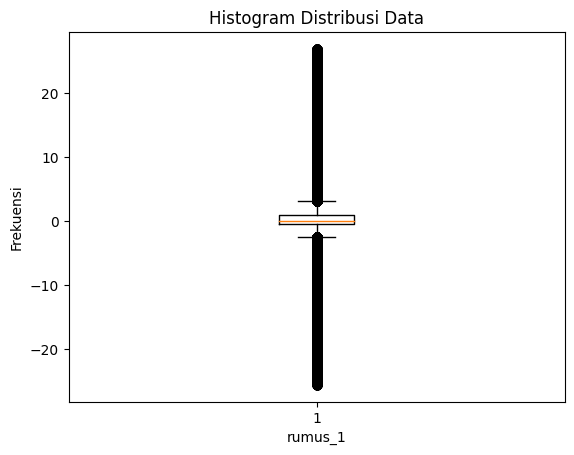

In [265]:
data = flux_c02_z['rumus_1']
# Membuat histogram
plt.boxplot(data)
plt.xlabel('rumus_1')
plt.ylabel('Frekuensi')
plt.title('Histogram Distribusi Data')
plt.show()

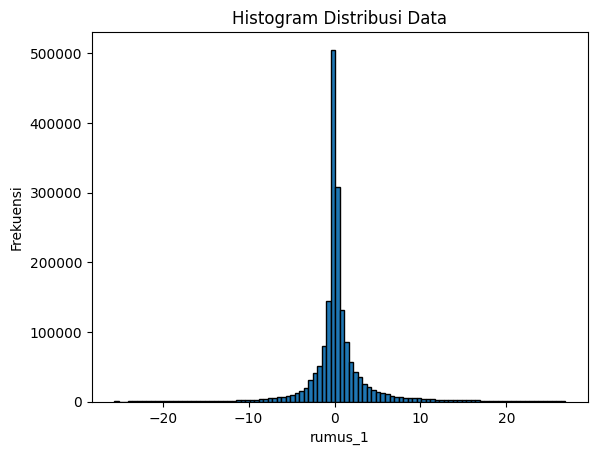

In [262]:

data = flux_c02_z['rumus_1']
# Membuat histogram
plt.hist(data, bins=100, edgecolor='black')
plt.xlabel('rumus_1')
plt.ylabel('Frekuensi')
plt.title('Histogram Distribusi Data')
plt.show()

In [69]:
flux_c02['rumus_1'] = flux_c02_z['rumus_1']

Mencari rumus2

In [70]:
# Menambahkan kolom tekanan udara kering
flux_c02['dry_pressure'] = flux_c02['bmp388Pressure'] - flux_c02['p_H2O']


# Misalkan flux_c02 adalah DataFrame yang berisi kolom suhu dan tekanan udara
R = 8.314  # Konstanta gas ideal dalam J/(mol·K)

# Menghitung hasil dan membalikkan langsung
flux_c02['rumus_2'] = 1 / (R * flux_c02['sht85Temp'] / flux_c02['dry_pressure'])

# Menghitung Fc
flux_c02['Fec'] = flux_c02['rumus_1']*flux_c02['rumus_2']

In [208]:
kolom=flux_c02[['rumus_1', 'rumus_2', 'Fc']]
print(kolom)

                          rumus_1   rumus_2        Fc
timestamp                                            
2024-06-11 00:06:01.364  0.000000  0.388882  0.000000
2024-06-11 00:06:01.439 -0.000000  0.501310 -0.000000
2024-06-11 00:06:01.601 -0.000000  0.501670 -0.000000
2024-06-11 00:06:01.763 -0.000000  0.501325 -0.000000
2024-06-11 00:06:01.925 -0.000000  0.501317 -0.000000
...                           ...       ...       ...
2024-06-17 23:36:00.314  8.818779  0.467692  4.124471
2024-06-17 23:36:00.477  8.832731  0.468481  4.137965
2024-06-17 23:36:00.644  8.812867  0.467693  4.121712
2024-06-17 23:36:00.806  8.822866  0.467966  4.128801
2024-06-17 23:36:00.969  8.822662  0.468217  4.130925

[1844521 rows x 3 columns]


In [71]:
flux_c02

,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas,w,w_30m,p_H2O_sat,RH_decimal,p_H2O,x_H2O,co2_dry,co2_dry_30m,w_aksen,co2_dry_aksen,rumus_1,dry_pressure,rumus_2,Fec
timestamp,,,,,,,,,,,,,,,,,,,,
2024-06-11 00:06:01.364,79.026558,98.419167,23.558025,632.0,0.00,0.0,0.00,0.000000,2.899918,0.984192,2.854076,0.036115,655.680149,655.680149,0.000000,0.000000,0.000000,76.172482,0.388910,0.000000
2024-06-11 00:06:01.439,101.172272,98.347450,23.587399,632.0,0.00,0.0,0.00,0.000000,2.905056,0.983475,2.857049,0.028239,650.365973,653.023061,0.000000,-2.657088,-0.000000,98.315223,0.501338,-0.000000
2024-06-11 00:06:01.601,101.174683,98.393227,23.571377,632.0,0.00,0.0,0.00,0.000000,2.902253,0.983932,2.855620,0.028225,650.356073,652.134065,0.000000,-1.777992,-0.000000,98.319062,0.501698,-0.000000
2024-06-11 00:06:01.763,101.174294,98.315407,23.587399,632.0,0.00,0.0,0.00,0.000000,2.905056,0.983154,2.856118,0.028230,650.359437,651.690408,0.000000,-1.330971,-0.000000,98.318176,0.501353,-0.000000
2024-06-11 00:06:01.925,101.174972,98.388649,23.587399,632.0,0.00,0.0,0.00,0.000000,2.905056,0.983886,2.858245,0.028251,650.373385,651.427004,0.000000,-1.053618,-0.000000,98.316727,0.501346,-0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-06-17 23:36:00.314,100.953239,94.857712,25.181582,506.0,5.27,0.0,-5.27,-4.869498,3.196128,0.948577,3.031774,0.030031,521.666410,543.684233,-0.400502,-22.017824,8.818184,97.921465,0.467719,4.124431
2024-06-17 23:36:00.477,100.955185,94.857712,25.141527,506.0,5.27,0.0,-5.27,-4.869534,3.188514,0.948577,3.024551,0.029959,521.627623,543.682238,-0.400466,-22.054616,8.832120,97.930634,0.468508,4.137918
2024-06-17 23:36:00.644,100.954712,94.898911,25.181582,506.0,5.27,0.0,-5.27,-4.869570,3.196128,0.948989,3.033091,0.030044,521.673189,543.680248,-0.400430,-22.007059,8.812278,97.921621,0.467720,4.121675


In [72]:
#resample Fec menjadi per detik
flux_c02_detik = flux_c02.resample('1S').mean()
print (flux_c02_detik)


                     bmp388Pressure  sht85Humi  sht85Temp         co2   
timestamp                                                               
2024-06-11 00:06:01       96.744556  98.372780  23.578320  632.000000  \
2024-06-11 00:06:02      101.176679  98.398822  23.609651  632.000000   
2024-06-11 00:06:03      101.176236  98.402382  23.605200  632.000000   
2024-06-11 00:06:04      101.176258  98.379494  23.606981  631.666667   
2024-06-11 00:06:05      101.176613  98.404416  23.609651  631.000000   
...                             ...        ...        ...         ...   
2024-06-17 23:35:56      100.953242  94.906540  25.171790  506.000000   
2024-06-17 23:35:57      100.954136  94.893061  25.154879  506.000000   
2024-06-17 23:35:58      100.953472  94.889755  25.179801  505.333333   
2024-06-17 23:35:59      100.953137  94.890627  25.154879  505.714286   
2024-06-17 23:36:00      100.954227  94.858475  25.170900  506.000000   

                        bawah  atas         w     

In [52]:
flux_c02_detik.head()

,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas,w,w_30m,p_H2O_sat,RH_decimal,p_H2O,x_H2O,co2_dry,co2_dry_30m,w_aksen,co2_dry_aksen,rumus_1,dry_pressure,rumus_2,Fec
timestamp,,,,,,,,,,,,,,,,,,,,
2024-06-11 00:06:01,96.744556,98.372780,23.578320,632.000000,0.0,0.0,0.0,0.0,2.903468,0.983728,2.856221,0.029812,651.427004,652.790937,0.0,-1.363934,0.0,93.888334,0.478929,0.0
2024-06-11 00:06:02,101.176679,98.398822,23.609651,632.000000,0.0,0.0,0.0,0.0,2.908954,0.983988,2.862376,0.028291,650.400394,651.032282,0.0,-0.631889,0.0,98.314303,0.500861,0.0
2024-06-11 00:06:03,101.176236,98.402382,23.605200,632.000000,0.0,0.0,0.0,0.0,2.908177,0.984024,2.861716,0.028284,650.396106,650.758489,0.0,-0.362383,0.0,98.314521,0.500957,0.0
2024-06-11 00:06:04,101.176258,98.379494,23.606981,631.666667,0.0,0.0,0.0,0.0,2.908489,0.983795,2.861357,0.028281,650.050683,650.626742,0.0,-0.576059,0.0,98.314901,0.500921,0.0
2024-06-11 00:06:05,101.176613,98.404416,23.609651,631.000000,0.0,0.0,0.0,0.0,2.908956,0.984044,2.862541,0.028293,649.372382,650.382065,0.0,-1.009683,0.0,98.314072,0.500860,0.0


In [73]:
Jumlah = flux_c02_detik['Fec'].sum()

print(f'jumlah NEE dalam 1 minggu ={Jumlah}')

jumlah NEE dalam 1 minggu =61077.29965860416


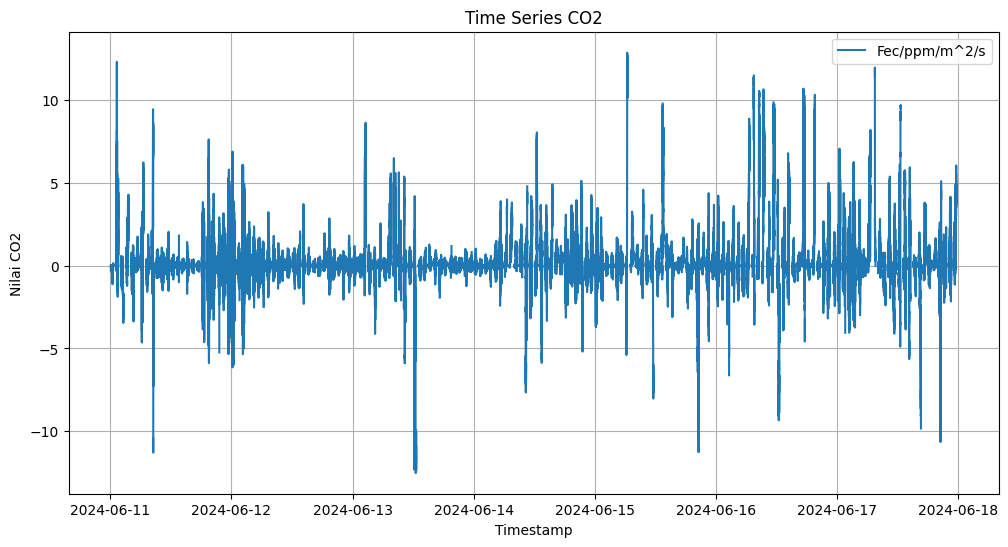

In [76]:
plt.figure(figsize=(12, 6))
plt.plot(flux_c02_detik.index,flux_c02_detik['Fec'], label="Fec/ppm/m^2/s")
plt.title('Time Series CO2')
plt.xlabel('Timestamp')
plt.ylabel('Nilai CO2')
plt.legend()
plt.grid()
plt.show()

Mencari F_storage

In [54]:
co2_st1 = pd.read_csv('data_st1.csv')
print(co2_st1.head())

                 timestamp  co2
0  2024-06-11 00:06:01.356  657
1  2024-06-11 00:06:01.434  657
2  2024-06-11 00:06:01.596  657
3  2024-06-11 00:06:01.758  657
4  2024-06-11 00:06:01.920  657


In [55]:
# Pastikan kolom 'timestamp' sebagai indeks
co2_st1.set_index('timestamp', inplace=True)

co2_st1.info()


<class 'pandas.core.frame.DataFrame'>
Index: 1836311 entries, 2024-06-11 00:06:01.356 to 2024-06-17 23:36:01.059
Data columns (total 1 columns):
 #   Column  Dtype
---  ------  -----
 0   co2     int64
dtypes: int64(1)
memory usage: 28.0+ MB


In [56]:
co2_st1.index = pd.to_datetime(co2_st1.index)

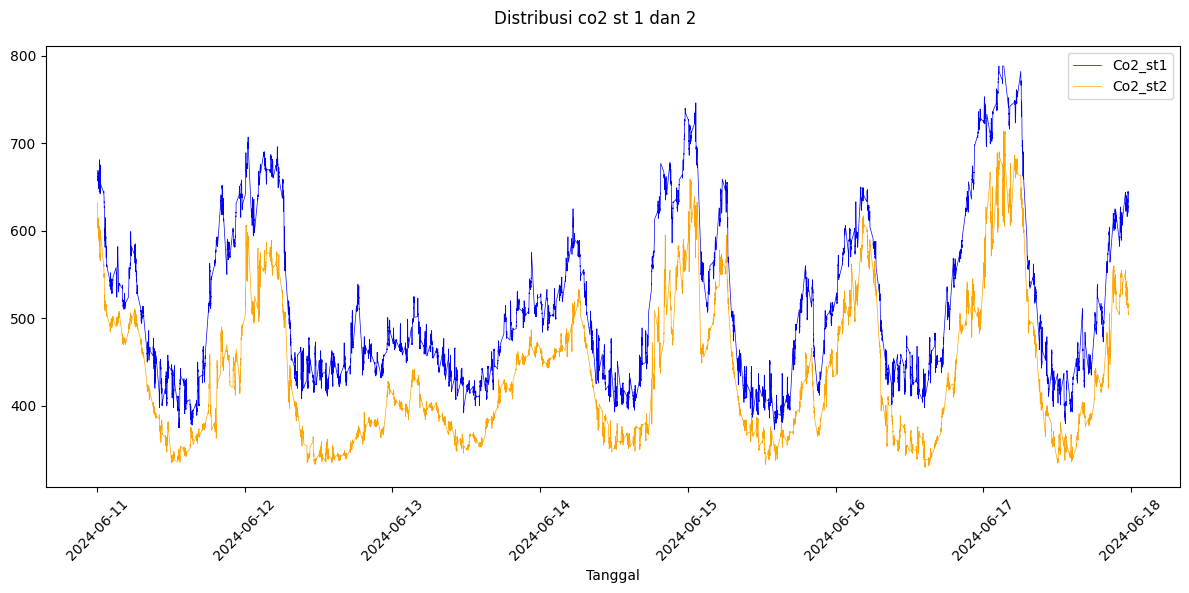

In [77]:
plt.figure(figsize=(12, 6))

plt.plot(co2_st1.index, co2_st1['co2'], label='Co2_st1', color='blue', linewidth=0.5)
plt.plot(flux_c02.index, flux_c02['co2'], label='Co2_st2', color='orange', linewidth=0.5)
plt.xlabel('Tanggal')
plt.legend()

plt.suptitle('Distribusi co2 st 1 dan 2')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [78]:
flux_c02_detik.head()

,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas,w,w_30m,p_H2O_sat,RH_decimal,p_H2O,x_H2O,co2_dry,co2_dry_30m,w_aksen,co2_dry_aksen,rumus_1,dry_pressure,rumus_2,Fec
timestamp,,,,,,,,,,,,,,,,,,,,
2024-06-11 00:06:01,96.744556,98.372780,23.578320,632.000000,0.0,0.0,0.0,0.0,2.903468,0.983728,2.856221,0.029812,651.427004,652.790937,0.0,-1.363934,0.0,93.888334,0.478929,0.0
2024-06-11 00:06:02,101.176679,98.398822,23.609651,632.000000,0.0,0.0,0.0,0.0,2.908954,0.983988,2.862376,0.028291,650.400394,651.032282,0.0,-0.631889,0.0,98.314303,0.500861,0.0
2024-06-11 00:06:03,101.176236,98.402382,23.605200,632.000000,0.0,0.0,0.0,0.0,2.908177,0.984024,2.861716,0.028284,650.396106,650.758489,0.0,-0.362383,0.0,98.314521,0.500957,0.0
2024-06-11 00:06:04,101.176258,98.379494,23.606981,631.666667,0.0,0.0,0.0,0.0,2.908489,0.983795,2.861357,0.028281,650.050683,650.626742,0.0,-0.576059,0.0,98.314901,0.500921,0.0
2024-06-11 00:06:05,101.176613,98.404416,23.609651,631.000000,0.0,0.0,0.0,0.0,2.908956,0.984044,2.862541,0.028293,649.372382,650.382065,0.0,-1.009683,0.0,98.314072,0.500860,0.0


In [81]:
#resample co2_st1
co2_st1_detik = co2_st1.resample('1s').mean()

In [82]:
# Menggabungkan flux_c02_detik dan co2_st1 berdasarkan kolom timestamp  
flux_sto = pd.merge(flux_c02_detik, co2_st1_detik, on='timestamp', how='left')  
  
# Menampilkan hasil  
print(flux_sto)

                     bmp388Pressure  sht85Humi  sht85Temp       co2_x   
timestamp                                                               
2024-06-11 00:06:01       96.744556  98.372780  23.578320  632.000000  \
2024-06-11 00:06:02      101.176679  98.398822  23.609651  632.000000   
2024-06-11 00:06:03      101.176236  98.402382  23.605200  632.000000   
2024-06-11 00:06:04      101.176258  98.379494  23.606981  631.666667   
2024-06-11 00:06:05      101.176613  98.404416  23.609651  631.000000   
...                             ...        ...        ...         ...   
2024-06-17 23:35:56      100.953242  94.906540  25.171790  506.000000   
2024-06-17 23:35:57      100.954136  94.893061  25.154879  506.000000   
2024-06-17 23:35:58      100.953472  94.889755  25.179801  505.333333   
2024-06-17 23:35:59      100.953137  94.890627  25.154879  505.714286   
2024-06-17 23:36:00      100.954227  94.858475  25.170900  506.000000   

                        bawah  atas         w     

In [86]:
#ganti nama kolom
flux_sto = flux_sto.rename(columns={
    'co2_x': 'co2_st_2',
    'co2_y': 'co2_st_1'
})



In [87]:
flux_sto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 603000 entries, 2024-06-11 00:06:01 to 2024-06-17 23:36:00
Data columns (total 21 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   bmp388Pressure  300742 non-null  float64
 1   sht85Humi       300742 non-null  float64
 2   sht85Temp       300742 non-null  float64
 3   co2_st_2        300742 non-null  float64
 4   bawah           300742 non-null  float64
 5   atas            300742 non-null  float64
 6   w               300742 non-null  float64
 7   w_30m           300742 non-null  float64
 8   p_H2O_sat       300742 non-null  float64
 9   RH_decimal      300742 non-null  float64
 10  p_H2O           300742 non-null  float64
 11  x_H2O           300742 non-null  float64
 12  co2_dry         300742 non-null  float64
 13  co2_dry_30m     300742 non-null  float64
 14  w_aksen         300742 non-null  float64
 15  co2_dry_aksen   300742 non-null  float64
 16  rumus_1         299109

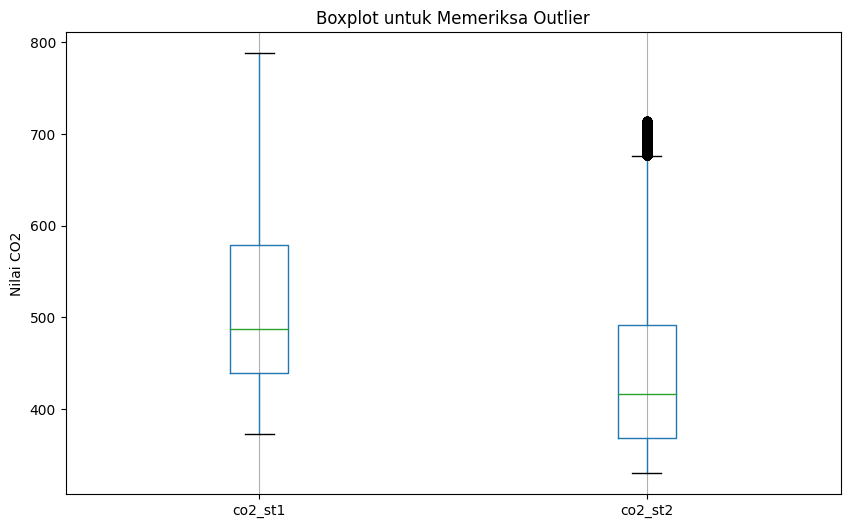

In [ ]:
columns = ['co2_st_1', 'co2_st_2']

# Membuat boxplot
plt.figure(figsize=(10, 6))
flux_sto[columns].boxplot()
plt.title('Boxplot untuk Memeriksa Outlier')
plt.ylabel('Nilai CO2')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [ ]:
# Ketinggian sensor (meter)
z = [3, 16]  # Ketinggian untuk st1, dan st2

# Hitung perubahan stok gas: dCO2/dt
# diff() menghitung perubahan antar baris
dt = 30 * 60  # 30 menit dalam detik
flux_sto['dco2_st1'] = flux_sto['co2_st_1'].diff() / dt
flux_sto['dco2_st2'] = flux_sto['co2_st_2'].diff() / dt


# Hitung integral perubahan stok gas menggunakan metode trapezoidal
def integrate_stock_change(dco2_dt_values, z):
    return np.trapz(dco2_dt_values, z)

flux_sto['flux_sto'] = flux_sto.apply(
    lambda row: integrate_stock_change(
        [row['dco2_st1'], row['dco2_st2']],
        z
    ), axis=1
)



In [89]:

# Hitung flux ecosystem
flux_sto['F_ecosystem'] = flux_sto['Fec'] + flux_sto['flux_sto']

# Hasil akhir
print(flux_sto)

                     bmp388Pressure  sht85Humi  sht85Temp    co2_st_2   
timestamp                                                               
2024-06-11 00:06:01       96.744556  98.372780  23.578320  632.000000  \
2024-06-11 00:06:02      101.176679  98.398822  23.609651  632.000000   
2024-06-11 00:06:03      101.176236  98.402382  23.605200  632.000000   
2024-06-11 00:06:04      101.176258  98.379494  23.606981  631.666667   
2024-06-11 00:06:05      101.176613  98.404416  23.609651  631.000000   
...                             ...        ...        ...         ...   
2024-06-17 23:35:56      100.953242  94.906540  25.171790  506.000000   
2024-06-17 23:35:57      100.954136  94.893061  25.154879  506.000000   
2024-06-17 23:35:58      100.953472  94.889755  25.179801  505.333333   
2024-06-17 23:35:59      100.953137  94.890627  25.154879  505.714286   
2024-06-17 23:36:00      100.954227  94.858475  25.170900  506.000000   

                        bawah  atas         w     

In [90]:
flux_sto

,bmp388Pressure,sht85Humi,sht85Temp,co2_st_2,bawah,atas,w,w_30m,p_H2O_sat,RH_decimal,...,co2_dry_aksen,rumus_1,dry_pressure,rumus_2,Fec,co2_st_1,dco2_st1,dco2_st2,flux_sto,F_ecosystem
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-11 00:06:01,96.744556,98.372780,23.578320,632.000000,0.000000,0.0,0.000000,0.000000,2.903468,0.983728,...,-1.363934,0.000000,93.888334,0.478929,0.000000,657.000000,NaN,NaN,NaN,NaN
2024-06-11 00:06:02,101.176679,98.398822,23.609651,632.000000,0.000000,0.0,0.000000,0.000000,2.908954,0.983988,...,-0.631889,0.000000,98.314303,0.500861,0.000000,657.000000,0.000000,0.000000,0.000000,0.000000
2024-06-11 00:06:03,101.176236,98.402382,23.605200,632.000000,0.000000,0.0,0.000000,0.000000,2.908177,0.984024,...,-0.362383,0.000000,98.314521,0.500957,0.000000,657.000000,0.000000,0.000000,0.000000,0.000000
2024-06-11 00:06:04,101.176258,98.379494,23.606981,631.666667,0.000000,0.0,0.000000,0.000000,2.908489,0.983795,...,-0.576059,0.000000,98.314901,0.500921,0.000000,657.000000,0.000000,-0.000185,-0.001204,-0.001204
2024-06-11 00:06:05,101.176613,98.404416,23.609651,631.000000,0.000000,0.0,0.000000,0.000000,2.908956,0.984044,...,-1.009683,0.000000,98.314072,0.500860,0.000000,657.000000,0.000000,-0.000370,-0.002407,-0.002407
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-06-17 23:35:56,100.953242,94.906540,25.171790,506.000000,5.350000,0.0,-5.350000,-4.868605,3.194269,0.949065,...,-22.066400,10.623223,97.921672,0.467902,4.970720,622.000000,-0.000185,0.000000,-0.001204,4.969516
2024-06-17 23:35:57,100.954136,94.893061,25.154879,506.000000,5.270000,0.0,-5.270000,-4.868837,3.191051,0.948931,...,-22.073105,8.854903,97.926050,0.468237,4.146196,622.000000,0.000000,0.000000,0.000000,4.146196
2024-06-17 23:35:58,100.953472,94.889755,25.179801,505.333333,5.316667,0.0,-5.316667,-4.869074,3.195792,0.948898,...,-22.724767,10.189663,97.920993,0.467750,4.767261,621.166667,-0.000463,-0.000370,-0.005417,4.761844


In [92]:
flux_sto.drop(columns={'dco2_st1','dco2_st2'}, inplace=True)

In [3]:
flux_sto = pd.read_csv('1_minggu_detik.csv')

In [4]:

tonase = 10 ** -6 #gram ke ton 10^-6
minggu = 52 # 52 minggu dalam 1 tahun
hektar = 10000 # 1 hektar 10,000 meter per segi

In [108]:
jumlah_NEE = flux_sto ['F_ecosystem'].sum() #flux ecosystem (ppm)
massa_co2 = 44.01 #gram per mol
suhu = flux_sto ['sht85Temp'].mean() # satuan C
T = suhu + 273.15
tekanan = flux_sto ['bmp388Pressure'].mean() #tekanan (kilopascal)
P = tekanan * 1000
R = 8.314 #konstanta gas ideal
n = 1000000 #konsentrasi seluruh gas diudara

#perhitungan 
hasil = (jumlah_NEE*massa_co2)/((n*R*T)/P)  
hasil = int(hasil)
print (f"NEE dalam ecosystem = {hasil} gram/m^3/minggu")

NEE dalam ecosystem = 108 gram/m^3/minggu


In [121]:
#simpan hasil data
flux_sto.to_csv('F_ecosytem.csv')
flux_c02.to_csv('F_ec_6hz.csv')



In [8]:
flux_sto['F_ecosystem'].describe()

count    298708.000000
mean          0.204832
std           1.558423
min         -12.508799
25%          -0.115702
50%           0.012757
75%           0.283527
max          12.871649
Name: F_ecosystem, dtype: float64

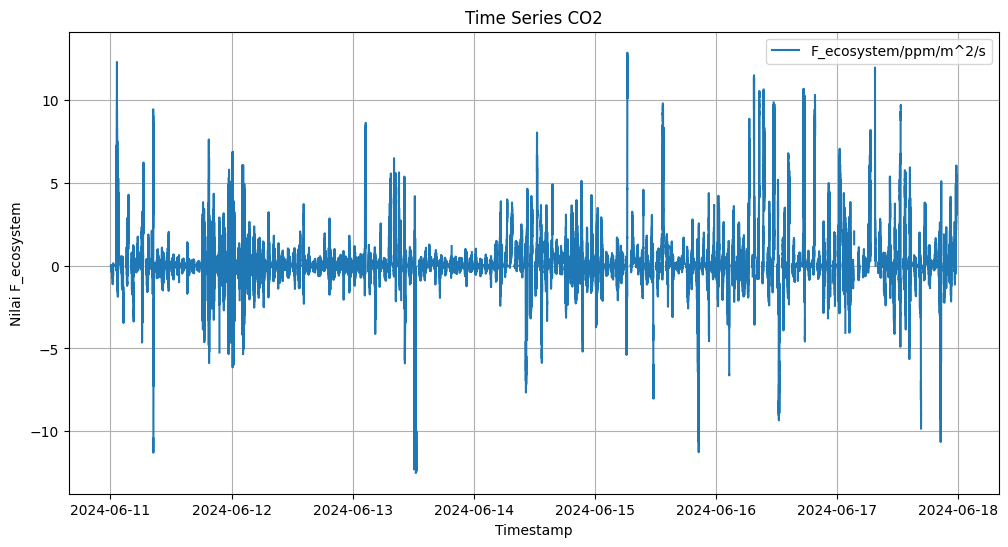

In [95]:
plt.figure(figsize=(12, 6))
plt.plot(flux_sto.index,flux_sto['F_ecosystem'], label="F_ecosystem/ppm/m^2/s")
plt.title('Time Series CO2')
plt.xlabel('Timestamp')
plt.ylabel('Nilai F_ecosystem')
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Hitung jumlah F_ecosystem positif dan negatif
jumlah_positif = int(flux_sto[flux_sto['F_ecosystem'] > 0]['F_ecosystem'].sum())
jumlah_negatif = int(flux_sto[flux_sto['F_ecosystem'] < 0]['F_ecosystem'].sum())

gramasi_1 = int((jumlah_positif*massa_co2)/((n*R*T)/P))
gramasi_2 = int((jumlah_negatif*massa_co2)/((n*R*T)/P))

print(f"Jumlah pelepasan co2 oleh ekosistem: {jumlah_positif} ppm atau {gramasi_1} g/m^3/minggu")
print(f"Jumlah penyerapan co2 oleh ekosistem: {jumlah_negatif} pm atau {gramasi_2} g/m^3/minggu")
